# EXP-Y8S-NEG-V03-001-CLASS-WEIGHTED — 3 lớp bệnh, ảnh âm đúng chuẩn YOLO

**Model:** `yolov8s.pt` · **Dataset:** `CASHEW_YOLO_MASTER_FINAL_NEG_V03 (2).zip` · **Class weighting:** `cls_pw=0.25`.

`data.yaml` phải có đúng 3 lớp detection: `0 anthracnose`, `1 leaf_miner`, `2 red_rust`.
`healthy` và `not_cashew_leaf` là **ảnh nền** với 0 bounding box; TXT rỗng được ưu tiên, TXT vắng cũng hợp lệ. Không tạo lớp thứ 4/5 và không loại ảnh vì nhãn rỗng.

Chạy các cell từ trên xuống đến **Preflight Audit** để kiểm tra dataset và dataloader. Báo cáo được lưu tại `metadata/negative_image_preflight.json`. Các cell tiếp theo dùng để train YOLOv8s khi đã sẵn sàng. Recipe train giữ từ V003: 640 px, 80 epoch tối đa, batch 8, seed 42, AdamW, LR 0.001, patience 20, mosaic 0.4, close mosaic 10, mixup 0; Test chỉ đánh giá cuối.

Preflight kiểm tra ảnh âm trong cấu hình dataset train thật. Khi kiểm tra 0 GT box trong batch, chỉ riêng loader kiểm toán tắt mosaic/mixup để tránh hộp từ ảnh khác ghép vào; tham số training vẫn giữ nguyên.


## 1. Import thư viện


In [1]:
import importlib.util, subprocess, sys
for package, module in [('ultralytics','ultralytics'),('pandas','pandas'),
                        ('matplotlib','matplotlib'),('Pillow','PIL'),('PyYAML','yaml')]:
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable,'-m','pip','install',package])
import csv, hashlib, inspect, json, os, platform, shutil, sys, time, warnings, zipfile
from collections import Counter, defaultdict
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
import yaml
import torch
import ultralytics
from ultralytics import YOLO
from ultralytics.cfg import DEFAULT_CFG_DICT
from ultralytics.models.yolo.detect.train import DetectionTrainer
from IPython.display import display

def save_json(path, obj):
    Path(path).write_text(json.dumps(obj, ensure_ascii=False, indent=2, default=str), encoding='utf-8')

def md5_file(path):
    digest = hashlib.md5()
    with Path(path).open('rb') as f:
        for block in iter(lambda: f.read(8 * 1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


## 2. Environment & GPU Information


In [2]:
ENVIRONMENT = {'python': sys.version.split()[0], 'torch': torch.__version__,
               'ultralytics': ultralytics.__version__, 'cuda_available': torch.cuda.is_available(),
               'gpu': torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
               'platform': platform.platform()}
print(json.dumps(ENVIRONMENT, ensure_ascii=False, indent=2))


{
  "python": "3.13.16",
  "torch": "2.11.0+cu130",
  "ultralytics": "8.4.198",
  "cuda_available": true,
  "gpu": "NVIDIA RTX PRO 6000 Blackwell Server Edition",
  "platform": "Linux-6.6.159+-x86_64-with-glibc2.39"
}


## 3. CONFIG — chỉnh đường dẫn trước khi chạy


In [3]:
# CONFIG: mọi lựa chọn thí nghiệm tập trung tại đây.
MODEL_WEIGHTS = 'yolov8s.pt'  # hoặc 'yolo26s.pt'
MODEL_TAG = {'yolo26s.pt': 'Y26S', 'yolov8s.pt': 'Y8S'}[MODEL_WEIGHTS]
EXPERIMENT_ID = f'EXP-{MODEL_TAG}-NEG-V03-001-CLASS-WEIGHTED'
ARCHIVE_PREFIX = f'EXP-{MODEL_TAG}-NEG-V03-001'
DATA_ROOT = None  # thư mục dataset đã giải nén, hoặc None
DATA_ZIP = None   # ZIP đã tải sẵn; None: tìm local rồi tải từ Drive ID bên dưới
DATASET_DRIVE_FILE_ID = '1cRQ-kR1lsEvyqvs0Qn8rhUS4mvdi4nD2'
DATASET_EXPECTED_BYTES = 246419660
DATA_SEARCH_ROOTS = [Path.cwd(), Path('/content'), Path('/kaggle/input'), Path('/kaggle/working')]
PREFERRED_ZIPS = ['CASHEW_YOLO_MASTER_FINAL_NEG_V03 (2).zip']
OUTPUT_ROOT = Path('/kaggle/working' if Path('/kaggle/working').exists() else
                   '/content' if Path('/content').exists() else Path.cwd()) / 'exp_yolo_neg_v03_weighted'
NOTEBOOK_SOURCE = None  # chỉ đặt khi muốn đóng gói một file .ipynb cụ thể trên runtime
BASELINE_METRICS = None  # metrics.json của NEG_V03 cls_pw=0 nếu có
OTHER_MODEL_METRICS = None  # metrics.json của model còn lại, hoặc None để tự tìm trong OUTPUT_ROOT
DRIVE_PARENT_FOLDER_ID = '1-Mrqs8Y9dwLexSKIVKBvyYvvQ8X8fXti'
UPLOAD_TO_DRIVE = True
FINAL_TEST_EVALUATION = False
IMGSZ, EPOCHS, BATCH, SEED = 640, 80, 8, 42
OPTIMIZER, LR0, PATIENCE = 'AdamW', 0.001, 20
CLS_PW, MOSAIC, CLOSE_MOSAIC, MIXUP = 0.25, 0.4, 10, 0.0
AMP = bool(torch.cuda.is_available())
DEVICE = 0 if torch.cuda.is_available() else 'cpu'
PRED_CONF, MATCH_IOU, LOW_CONF = 0.05, 0.50, 0.25
EXPECTED_COUNTS = {}  # dataset mới; dùng số thực tế từ preflight
CLASS_NAMES = ['anthracnose', 'leaf_miner', 'red_rust']
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
RUN_DIR = OUTPUT_ROOT / EXPERIMENT_ID
RUN_DIR.mkdir(parents=True, exist_ok=True)
CONFIG = {k: str(v) if isinstance(v, Path) else v for k, v in globals().copy().items()
          if k in {'MODEL_WEIGHTS','EXPERIMENT_ID','DATA_ROOT','DATA_ZIP','DATASET_DRIVE_FILE_ID','DATASET_EXPECTED_BYTES','OUTPUT_ROOT',
                   'BASELINE_METRICS','OTHER_MODEL_METRICS','DRIVE_PARENT_FOLDER_ID','UPLOAD_TO_DRIVE',
                   'FINAL_TEST_EVALUATION','IMGSZ','EPOCHS','BATCH','SEED','OPTIMIZER',
                   'LR0','PATIENCE','CLS_PW','MOSAIC','CLOSE_MOSAIC','MIXUP','AMP','DEVICE'}}
save_json(RUN_DIR / 'experiment_config.json', CONFIG)
print('Experiment:', EXPERIMENT_ID, '| output:', RUN_DIR)


Experiment: EXP-Y8S-NEG-V03-001-CLASS-WEIGHTED | output: /content/exp_yolo_neg_v03_weighted/EXP-Y8S-NEG-V03-001-CLASS-WEIGHTED


## 4. Dataset Loading & Validation

Tải `CASHEW_YOLO_MASTER_FINAL_NEG_V03 (2).zip` từ Drive ID `1cRQ-kR1lsEvyqvs0Qn8rhUS4mvdi4nD2` hoặc đặt `DATA_ZIP`/`DATA_ROOT`. ZIP/thư mục nguồn chỉ đọc; notebook làm việc trên bản sao. `data_fixed.yaml` giữ đúng 3 class IDs. Ảnh không có nhãn hoặc nhãn rỗng vẫn được giữ.


In [4]:
def safe_extract(archive, target):
    target = Path(target).resolve()
    with zipfile.ZipFile(archive) as z:
        for info in z.infolist():
            dest = (target / info.filename).resolve()
            if not dest.is_relative_to(target):
                raise ValueError(f'Unsafe ZIP member: {info.filename}')
        z.extractall(target)

def find_archive():
    if DATA_ZIP:
        p = Path(DATA_ZIP).expanduser()
        if not p.is_file(): raise FileNotFoundError(p)
        return p
    for name in PREFERRED_ZIPS:
        for root in DATA_SEARCH_ROOTS:
            if root.exists():
                hits = list(root.glob(name)) + list(root.glob('*/' + name))
                if hits: return hits[0]
    destination = OUTPUT_ROOT / PREFERRED_ZIPS[0]
    if destination.is_file(): return destination
    try:
        for package,module in [('google-auth','google.auth'),
                               ('google-api-python-client','googleapiclient')]:
            try: found = importlib.util.find_spec(module)
            except ModuleNotFoundError: found = None
            if found is None: subprocess.check_call([sys.executable,'-m','pip','install',package])
        import google.auth
        from googleapiclient.discovery import build
        from googleapiclient.http import MediaIoBaseDownload
        try:
            from google.colab import auth
            auth.authenticate_user()
        except ImportError:
            pass
        credentials,_ = google.auth.default(scopes=['https://www.googleapis.com/auth/drive.readonly'])
        service = build('drive','v3',credentials=credentials,cache_discovery=False)
        meta = service.files().get(fileId=DATASET_DRIVE_FILE_ID,
            fields='id,name,size,md5Checksum,mimeType',supportsAllDrives=True).execute()
        if meta['name'] != PREFERRED_ZIPS[0] or not meta['name'].lower().endswith('.zip'):
            raise ValueError(f'Drive ID trỏ đến file khác: {meta}')
        request = service.files().get_media(fileId=DATASET_DRIVE_FILE_ID,supportsAllDrives=True)
        partial = destination.with_suffix('.zip.part')
        with partial.open('wb') as stream:
            downloader = MediaIoBaseDownload(stream,request,chunksize=8*1024*1024)
            done = False
            while not done:
                progress,done = downloader.next_chunk(num_retries=3)
                print('Dataset download:',f'{progress.progress():.0%}')
        if partial.stat().st_size != int(meta['size']):
            raise RuntimeError('Dataset download sai dung lượng')
        if meta.get('md5Checksum') and md5_file(partial) != meta['md5Checksum']:
            raise RuntimeError('Dataset download sai MD5')
        partial.replace(destination)
        return destination
    except Exception as exc:
        raise RuntimeError('Không tải được dataset từ Drive. Trên Colab đăng nhập Google; '
            'trên Kaggle cấp Application Default Credentials, hoặc đặt DATA_ZIP/DATA_ROOT. '
            f'Chi tiết: {type(exc).__name__}: {exc}') from exc

def reset_working_copy(target):
    if not target.resolve().is_relative_to(RUN_DIR.resolve()):
        raise RuntimeError('Chỉ được thay bản sao nằm trong RUN_DIR')
    if target.exists(): shutil.rmtree(target)

if DATA_ROOT:
    source_dir = Path(DATA_ROOT).expanduser().resolve()
    if not source_dir.is_dir(): raise FileNotFoundError(source_dir)
    source_archive = None
    dataset_root = RUN_DIR / 'dataset_working_copy'
    reset_working_copy(dataset_root)
    shutil.copytree(source_dir, dataset_root)
else:
    source_archive = find_archive()
    dataset_root = RUN_DIR / 'dataset_working_copy'
    if source_archive.stat().st_size != DATASET_EXPECTED_BYTES:
        raise RuntimeError(f'Sai ZIP: {source_archive.stat().st_size} bytes; cần {DATASET_EXPECTED_BYTES}')
    dataset_root.mkdir(parents=True, exist_ok=True)
    marker = dataset_root / '.source_md5'
    digest = md5_file(source_archive)
    if marker.exists() and marker.read_text(encoding='ascii') != digest:
        reset_working_copy(dataset_root)
        dataset_root.mkdir(parents=True, exist_ok=True)
    if not marker.exists():
        if any(dataset_root.iterdir()):
            reset_working_copy(dataset_root)
            dataset_root.mkdir(parents=True, exist_ok=True)
        safe_extract(source_archive, dataset_root)
        marker.write_text(digest, encoding='ascii')
    print('Archive:', source_archive)

def find_split(root, split):
    aliases = ['val', 'valid', 'validation'] if split == 'val' else [split]
    candidates = []
    for alias in aliases:
        candidates += list(root.rglob(f'images/{alias}')) + list(root.rglob(f'{alias}/images'))
    candidates = [p for p in candidates if p.is_dir()]
    if len(candidates) != 1:
        raise RuntimeError(f'Cần đúng một images/{split} hoặc {split}/images; thấy: {candidates}')
    im = candidates[0]
    lab = im.parent.parent / 'labels' / im.name if im.parent.name == 'images' else im.parent / 'labels'
    if not lab.is_dir(): raise FileNotFoundError(f'Không thấy labels cho {im}: {lab}')
    return im, lab

SPLITS = {s: find_split(dataset_root, s) for s in ('train','val','test')}
# Cache chỉ bị xóa trong bản sao làm việc, để Ultralytics quét lại nhãn mới.
for cache_file in dataset_root.rglob('*.cache'):
    cache_file.unlink()
yaml_candidates = [p for p in dataset_root.rglob('*.yaml')
                   if p.name.lower() in {'data.yaml', 'dataset.yaml'}]
if not yaml_candidates:
    raise RuntimeError('Không tìm thấy data.yaml/dataset.yaml trong dataset')
for original_yaml in yaml_candidates:
    spec = yaml.safe_load(original_yaml.read_text(encoding='utf-8')) or {}
    names = spec.get('names')
    if isinstance(names, dict):
        names = [names.get(i, names.get(str(i))) for i in range(len(names))]
    if names != CLASS_NAMES or spec.get('nc', 3) != 3:
        raise RuntimeError(f'{original_yaml}: cần đúng 3 lớp theo thứ tự {CLASS_NAMES}; nhận {names}')
print('Class IDs:', dict(enumerate(CLASS_NAMES)))

def images_in(root):
    return sorted(p for p in root.rglob('*') if p.suffix.lower() in {'.jpg','.jpeg','.png','.webp'})

def label_for(image, image_dir, label_dir):
    return label_dir / image.relative_to(image_dir).with_suffix('.txt')

def read_labels(label):
    rows = []
    seen = set()
    if not label.exists(): return rows  # ảnh âm tính hợp lệ
    for line_no, line in enumerate(label.read_text(encoding='utf-8-sig').splitlines(), 1):
        parts = line.split()
        if len(parts) != 5: raise ValueError(f'{label}:{line_no}: cần class x y w h')
        values = [float(x) for x in parts]
        cls = values[0]
        if not cls.is_integer() or int(cls) not in range(3): raise ValueError(f'{label}:{line_no}: class sai')
        x,y,w,h = values[1:]
        if not all(np.isfinite(values)) or not (0 <= x <= 1 and 0 <= y <= 1 and 0 < w <= 1 and 0 < h <= 1):
            raise ValueError(f'{label}:{line_no}: box sai')
        if x-w/2 < -1e-6 or y-h/2 < -1e-6 or x+w/2 > 1+1e-6 or y+h/2 > 1+1e-6:
            raise ValueError(f'{label}:{line_no}: box vượt ảnh')
        row = (int(cls), x,y,w,h)
        if row not in seen:
            seen.add(row)
            rows.append(row)
    return rows

SPLIT_IMAGES = {s: images_in(pair[0]) for s, pair in SPLITS.items()}
for s in ('train', 'val', 'test'):
    if not SPLIT_IMAGES[s]: raise RuntimeError(f'{s}: split rỗng.')
ORPHAN_EMPTY_LABELS, ORPHAN_POSITIVE_LABELS = {}, {}
for s, (im_dir, lab_dir) in SPLITS.items():
    for im in SPLIT_IMAGES[s]:
        with Image.open(im) as image: image.verify()
        read_labels(label_for(im, im_dir, lab_dir))
    # Đối chiếu label với ảnh thực tế, không giả định đuôi .jpg viết thường.
    expected_labels = {label_for(im, im_dir, lab_dir).resolve() for im in SPLIT_IMAGES[s]}
    orphans = sorted(p for p in lab_dir.rglob('*')
                     if p.is_file() and p.suffix.lower() == '.txt'
                     and p.resolve() not in expected_labels)
    ORPHAN_EMPTY_LABELS[s] = [p for p in orphans if not p.read_text(encoding='utf-8-sig').strip()]
    ORPHAN_POSITIVE_LABELS[s] = [p for p in orphans if p.read_text(encoding='utf-8-sig').strip()]
    if orphans:
        print(f'{s}: {len(ORPHAN_EMPTY_LABELS[s])} TXT rỗng không có ảnh, '
              f'{len(ORPHAN_POSITIVE_LABELS[s])} TXT có box không có ảnh')
print('Test anthracnose_346:', any(p.stem == 'anthracnose_346' for p in SPLIT_IMAGES['test']))
# Chuẩn hóa data.yaml, không chỉnh file gốc.
DATA_YAML = RUN_DIR / 'data_fixed.yaml'
data_spec = {'path': str(dataset_root.resolve()), 'train': str(SPLITS['train'][0].resolve()),
             'val': str(SPLITS['val'][0].resolve()), 'test': str(SPLITS['test'][0].resolve()),
             'nc': 3, 'names': CLASS_NAMES}
DATA_YAML.write_text(yaml.safe_dump(data_spec, allow_unicode=True, sort_keys=False), encoding='utf-8')
print('Dataset xác minh:', {s: len(v) for s,v in SPLIT_IMAGES.items()}, '| YAML:', DATA_YAML)


Dataset download: 3%
Dataset download: 7%
Dataset download: 10%
Dataset download: 14%
Dataset download: 17%
Dataset download: 20%
Dataset download: 24%
Dataset download: 27%
Dataset download: 31%
Dataset download: 34%
Dataset download: 37%
Dataset download: 41%
Dataset download: 44%
Dataset download: 48%
Dataset download: 51%
Dataset download: 54%
Dataset download: 58%
Dataset download: 61%
Dataset download: 65%
Dataset download: 68%
Dataset download: 71%
Dataset download: 75%
Dataset download: 78%
Dataset download: 82%
Dataset download: 85%
Dataset download: 89%
Dataset download: 92%
Dataset download: 95%
Dataset download: 99%
Dataset download: 100%
Archive: /content/exp_yolo_neg_v03_weighted/CASHEW_YOLO_MASTER_FINAL_NEG_V03 (2).zip
Class IDs: {0: 'anthracnose', 1: 'leaf_miner', 2: 'red_rust'}
train: 25 TXT rỗng không có ảnh, 0 TXT có box không có ảnh
val: 2 TXT rỗng không có ảnh, 0 TXT có box không có ảnh
Test anthracnose_346: True
Dataset xác minh: {'train': 3497, 'val': 951, 'test'

## 5. Dataset Statistics — số ảnh, bounding box và phân bố lớp


In [5]:
dataset_digest = hashlib.sha256()
dataset_digest.update(json.dumps(CLASS_NAMES).encode('utf-8'))
for split, ims in SPLIT_IMAGES.items():
    im_dir, lab_dir = SPLITS[split]
    for im in ims:
        label = label_for(im, im_dir, lab_dir)
        dataset_digest.update(f'{split}/{im.relative_to(im_dir)}|{im.stat().st_size}|'.encode())
        if label.exists(): dataset_digest.update(label.read_bytes())
DATASET_STATS = {'source_archive': str(source_archive) if source_archive else None,
                 'source_md5': md5_file(source_archive) if source_archive else None,
                 'dataset_fingerprint': dataset_digest.hexdigest(), 'splits': {}}
for split, ims in SPLIT_IMAGES.items():
    im_dir, lab_dir = SPLITS[split]
    counts = Counter()
    negatives = 0
    for im in ims:
        rows = read_labels(label_for(im, im_dir, lab_dir))
        counts.update(r[0] for r in rows)
        negatives += not bool(rows)
    DATASET_STATS['splits'][split] = {'images': len(ims), 'negative_images': negatives,
                                      'boxes': {CLASS_NAMES[c]: counts[c] for c in range(3)},
                                      'total_boxes': sum(counts.values())}
save_json(RUN_DIR / 'dataset_statistics.json', DATASET_STATS)
display(pd.DataFrame(DATASET_STATS['splits']).T)
pd.DataFrame(DATASET_STATS['splits']).T.to_csv(RUN_DIR / 'dataset_statistics.csv')


,images,negative_images,boxes,total_boxes
train,3497,621,"{'anthracnose': 34886, 'leaf_miner': 2076, 're...",110033
val,951,58,"{'anthracnose': 14507, 'leaf_miner': 568, 'red...",47258
test,412,0,"{'anthracnose': 2907, 'leaf_miner': 372, 'red_...",17670


## 5a. Negative Image Preflight Audit — chạy đến đây để xác minh dữ liệu

Kiểm tra nhãn, ảnh âm/dương, trùng lặp giữa split và các batch từ Ultralytics. Đọc `metadata/negative_image_preflight.json` trước khi chạy các cell train. Warning `backgrounds`/empty/missing label là bình thường nếu ảnh thật sự không có bệnh; lỗi ảnh hỏng hoặc class/box sai sẽ dừng.


In [6]:
"""Notebook cell source: audit negative images through Ultralytics datasets and loaders."""

from ultralytics.cfg import IterableSimpleNamespace
from ultralytics.data import build_dataloader, build_yolo_dataset

PREFLIGHT_PATH = RUN_DIR / 'metadata' / 'negative_image_preflight.json'
PREFLIGHT_PATH.parent.mkdir(parents=True, exist_ok=True)
preflight = {
    'dataset': str(dataset_root),
    'data_yaml': str(DATA_YAML),
    'ultralytics_version': ultralytics.__version__,
    'class_names': CLASS_NAMES,
    'splits': {},
    'cross_split_exact_duplicates': [],
    'cross_split_same_names': [],
    'cross_split_perceptual_candidates': [],
    'errors': [],
    'warnings': [],
}

def negative_group(path):
    # Only the newly added *_neg_* images are negative by naming convention.
    # A legacy image such as healthy_1520.jpg may contain genuine disease GT.
    name = Path(path).stem.lower().replace('-', '_').replace(' ', '_')
    if name.startswith(('not_cashew_neg_', 'non_cashew_neg_')):
        return 'not_cashew_leaf'
    if name.startswith('healthy_neg_'):
        return 'healthy'
    return None

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

all_image_hashes = defaultdict(list)
all_image_names = defaultdict(list)
all_perceptual_hashes = defaultdict(list)
for split in ('train', 'val', 'test'):
    image_dir, label_dir = SPLITS[split]
    # Counter omits keys that never increment (for example Test can have 0
    # negatives). Keep all report fields present even when their value is 0.
    counts = Counter({'images': 0, 'boxes': 0, 'raw_box_lines': 0,
                      'duplicate_box_lines': 0, 'positive_images': 0,
                      'negative_images': 0, 'empty_label_files': 0,
                      'missing_label_files': 0})
    groups = Counter()
    negative_paths = set()
    duplicate_annotation_examples = []
    for image in SPLIT_IMAGES[split]:
        label = label_for(image, image_dir, label_dir)
        rows = read_labels(label)
        raw_box_lines = (sum(bool(line.strip()) for line in
                             label.read_text(encoding='utf-8-sig').splitlines())
                         if label.exists() else 0)
        group = negative_group(image.relative_to(image_dir))
        counts['images'] += 1
        counts['boxes'] += len(rows)
        counts['raw_box_lines'] += raw_box_lines
        counts['duplicate_box_lines'] += raw_box_lines - len(rows)
        if raw_box_lines > len(rows) and len(duplicate_annotation_examples) < 10:
            duplicate_annotation_examples.append(str(label))
        if rows:
            counts['positive_images'] += 1
            if group:
                preflight['errors'].append(f'{split}: {group} có box: {image}')
        else:
            counts['negative_images'] += 1
            negative_paths.add(str(image.resolve()))
            groups[group or 'unclassified'] += 1
            if label.exists():
                counts['empty_label_files'] += 1
                if label.stat().st_size:
                    preflight['warnings'].append(f'{split}: nhãn âm chỉ chứa whitespace: {label}')
            else:
                counts['missing_label_files'] += 1
                if group:
                    preflight['warnings'].append(f'{split}: {group} thiếu TXT rỗng (YOLO vẫn hỗ trợ): {label}')
            if any(token in image.stem.lower() for token in ('anthracnose', 'leaf_miner', 'red_rust')):
                preflight['errors'].append(f'{split}: tên ảnh bệnh nhưng không có box: {image}')
        digest = sha256_file(image)
        all_image_hashes[digest].append((split, str(image.relative_to(image_dir))))
        all_image_names[image.name.lower()].append((split, str(image.relative_to(image_dir))))
        with Image.open(image) as im:
            pixels = np.asarray(im.convert('L').resize((9, 8)))
        dhash = ''.join('1' if x else '0' for x in (pixels[:, 1:] > pixels[:, :-1]).flat)
        all_perceptual_hashes[dhash].append((split, str(image.relative_to(image_dir))))
    if split in ('train', 'val') and counts['positive_images'] == 0:
        preflight['errors'].append(f'{split}: không có nhãn dương hợp lệ')
    if split in ('train', 'val') and counts['negative_images'] == 0:
        preflight['errors'].append(f'{split}: không có ảnh âm để nạp vào dataloader')
    preflight['splits'][split] = {
        **dict(counts),
        'negative_groups': dict(groups),
        'negative_paths': negative_paths,
        'duplicate_annotation_examples': duplicate_annotation_examples,
        'orphan_empty_labels': {
            'count': len(ORPHAN_EMPTY_LABELS[split]),
            'examples': [str(p) for p in ORPHAN_EMPTY_LABELS[split][:10]],
        },
        'orphan_positive_labels': {
            'count': len(ORPHAN_POSITIVE_LABELS[split]),
            'examples': [str(p) for p in ORPHAN_POSITIVE_LABELS[split][:10]],
        },
    }
    if ORPHAN_EMPTY_LABELS[split]:
        preflight['warnings'].append(
            f'{split}: {len(ORPHAN_EMPTY_LABELS[split])} TXT rỗng không có ảnh; '
            'các file này không được dataloader dùng')
    if counts['duplicate_box_lines']:
        preflight['warnings'].append(
            f'{split}: {counts["duplicate_box_lines"]} dòng box trùng; '
            'Ultralytics tự khử trùng khi nạp, TXT nguồn không bị sửa')
    if ORPHAN_POSITIVE_LABELS[split]:
        preflight['errors'].append(
            f'{split}: {len(ORPHAN_POSITIVE_LABELS[split])} TXT có box không có ảnh tương ứng')
    if groups['unclassified']:
        preflight['warnings'].append(
            f'{split}: {groups["unclassified"]} ảnh 0 box không nhận ra nhóm từ tên; cần kiểm tra thủ công')

for digest, locations in all_image_hashes.items():
    if len({split for split, _ in locations}) > 1:
        preflight['cross_split_exact_duplicates'].append({'sha256': digest, 'locations': locations})
for name, locations in all_image_names.items():
    if len({split for split, _ in locations}) > 1:
        preflight['cross_split_same_names'].append({'name': name, 'locations': locations})
for dhash, locations in all_perceptual_hashes.items():
    if len({split for split, _ in locations}) > 1:
        preflight['cross_split_perceptual_candidates'].append(
            {'dhash': dhash, 'locations': locations})
if preflight['cross_split_exact_duplicates']:
    preflight['errors'].append('Có ảnh trùng byte giữa các split; xem cross_split_exact_duplicates')
if preflight['cross_split_same_names']:
    preflight['warnings'].append('Có tên file trùng giữa các split; xem cross_split_same_names')
if preflight['cross_split_perceptual_candidates']:
    preflight['warnings'].append('Có ảnh cùng perceptual hash giữa các split; kiểm tra nguồn thủ công')

train_cfg = {**DEFAULT_CFG_DICT, 'imgsz': IMGSZ, 'task': 'detect',
             'mosaic': MOSAIC, 'mixup': MIXUP, 'close_mosaic': CLOSE_MOSAIC,
             'cache': False, 'fraction': 1.0, 'classes': None,
             'single_cls': False, 'rect': False}
data_for_loader = yaml.safe_load(DATA_YAML.read_text(encoding='utf-8'))

def inspect_ultralytics_dataset(split, mode, config):
    image_dir, _ = SPLITS[split]
    dataset = build_yolo_dataset(IterableSimpleNamespace(**config),
                                 str(image_dir), BATCH, data_for_loader,
                                 mode=mode, rect=False, stride=32)
    expected = {str(p.resolve()) for p in SPLIT_IMAGES[split]}
    actual = {str(Path(p).resolve()) for p in dataset.im_files}
    label_lookup = {str(Path(row['im_file']).resolve()): len(row['cls'])
                    for row in dataset.labels}
    if actual != expected or set(label_lookup) != expected:
        preflight['errors'].append(f'{split}/{mode}: YOLODataset thiếu ảnh: '
                                   f'missing={len(expected-actual)}, extra={len(actual-expected)}')
    negative_paths = preflight['splits'][split]['negative_paths']
    loaded_boxes = sum(label_lookup.values())
    if loaded_boxes != preflight['splits'][split]['boxes']:
        preflight['errors'].append(
            f'{split}/{mode}: Ultralytics nạp {loaded_boxes} box, file nhãn có '
            f'{preflight["splits"][split]["boxes"]} box')
    for path in negative_paths & set(label_lookup):
        if label_lookup[path] != 0:
            preflight['errors'].append(f'{split}/{mode}: ảnh âm có GT box trong dataset: {path}')
    return dataset, {
        'images': len(dataset),
        'negative_images_accessible': len(negative_paths & actual),
        'positive_images_accessible': len(actual - negative_paths),
        'boxes_accessible': loaded_boxes,
    }

# Kiểm tra cấu hình train thật trên YOLODataset.labels. Mosaic có thể ghép thêm
# box vào tensor của một ảnh âm, vì vậy batch 0 GT được kiểm bằng train loader
# với augmentation trộn ảnh tắt riêng cho bước kiểm toán.
_, train_config_dataset = inspect_ultralytics_dataset('train', 'train', train_cfg)
preflight['splits']['train']['train_config_dataset'] = train_config_dataset

audit_cfg = {**train_cfg, 'mosaic': 0.0, 'mixup': 0.0,
             'cutmix': 0.0, 'copy_paste': 0.0}
for split, mode in (('train', 'train'), ('val', 'val')):
    dataset, dataset_summary = inspect_ultralytics_dataset(split, mode, audit_cfg)
    loader = build_dataloader(dataset, batch=BATCH, workers=0,
                              shuffle=False, rank=-1, device='cpu')
    seen = set()
    seen_negative = set()
    sample_batches = []
    for batch_number, batch in enumerate(loader):
        files = [str(Path(p).resolve()) for p in batch['im_file']]
        indices = batch['batch_idx'].reshape(-1).tolist()
        gt_per_image = Counter(int(i) for i in indices)
        batch_negatives = []
        for i, path in enumerate(files):
            if path in seen:
                preflight['errors'].append(f'{split}: dataloader lặp ảnh: {path}')
            seen.add(path)
            if path in preflight['splits'][split]['negative_paths']:
                seen_negative.add(path)
                batch_negatives.append(path)
                if gt_per_image[i] != 0:
                    preflight['errors'].append(f'{split}: batch ảnh âm có {gt_per_image[i]} GT box: {path}')
        if batch_negatives and len(sample_batches) < 5:
            sample_batches.append({'batch_index': batch_number,
                                   'images': len(files),
                                   'negative_images': [str(Path(p).name) for p in batch_negatives],
                                   'negative_gt_boxes': 0})
    expected = {str(p.resolve()) for p in SPLIT_IMAGES[split]}
    if seen != expected:
        preflight['errors'].append(f'{split}: dataloader thiếu {len(expected-seen)} ảnh, '
                                   f'dư {len(seen-expected)} ảnh')
    split_report = preflight['splits'][split]
    split_report['audit_dataset'] = dataset_summary
    split_report['dataloader'] = {
        'images_seen': len(seen),
        'negative_images_seen': len(seen_negative),
        'negative_images_expected': split_report['negative_images'],
        'sample_batches_with_negatives': sample_batches,
        'mix_augmentations_disabled_for_zero_gt_check': True,
    }
    if len(seen_negative) != split_report['negative_images']:
        preflight['errors'].append(f'{split}: loader không nạp đủ ảnh âm')

for split in preflight['splits']:
    preflight['splits'][split]['negative_paths'] = sorted(preflight['splits'][split]['negative_paths'])
preflight['status'] = 'pass' if not preflight['errors'] else 'fail'
save_json(PREFLIGHT_PATH, preflight)
print('Preflight:', preflight['status'], '| report:', PREFLIGHT_PATH)
for split, info in preflight['splits'].items():
    print(split, 'images:', info.get('images', 0), 'positive:', info.get('positive_images', 0),
          'negative:', info.get('negative_images', 0), 'groups:', info.get('negative_groups', {}))
    if 'dataloader' in info:
        print('  loader negatives:', info['dataloader']['negative_images_seen'])
if preflight['errors']:
    raise RuntimeError('Preflight phát hiện lỗi; xem metadata/negative_image_preflight.json: '
                       + '; '.join(preflight['errors'][:3]))


train: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3616.6±1696.8 MB/s, size: 38.7 KB)
train: Scanning /content/exp_yolo_neg_v03_weighted/EXP-Y8S-NEG-V03-001-CLASS-WEIGHTED/dataset_working_copy/CASHEW_YOLO_MASTER_FINAL_NEG_V03/labels/train... 3497 images, 621 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 3497/3497 5.8Kit/s 0.6s0.1s
train: /content/exp_yolo_neg_v03_weighted/EXP-Y8S-NEG-V03-001-CLASS-WEIGHTED/dataset_working_copy/CASHEW_YOLO_MASTER_FINAL_NEG_V03/images/train/anthracnose_681.jpg: 1 duplicate labels removed
train: /content/exp_yolo_neg_v03_weighted/EXP-Y8S-NEG-V03-001-CLASS-WEIGHTED/dataset_working_copy/CASHEW_YOLO_MASTER_FINAL_NEG_V03/images/train/red_rust_372.jpg: 1 duplicate labels removed
train: New cache created: /content/exp_yolo_neg_v03_weighted/EXP-Y8S-NEG-V03-001-CLASS-WEIGHTED/dataset_working_copy/CASHEW_YOLO_MASTER_FINAL_NEG_V03/labels/train.cache
albumentations: Blur(p=0.01, blur_limit=(3, 7)), MedianBlur(p=0.01, blur_limit=(3, 7)), ToGray(p=0.01, method='weighted_

## 6. Class Weight Calculation & Verification

Tính trọng số từ **bounding box Train của 3 lớp bệnh**. Ảnh âm không thêm class, không làm tăng số box. `cls_pw=0.25` như V003.


In [7]:
train_counts = np.array([DATASET_STATS['splits']['train']['boxes'][n] for n in CLASS_NAMES], dtype=float)
if np.any(train_counts <= 0): raise RuntimeError('Có lớp không có box Train.')
raw_weights = (1.0 / train_counts) ** CLS_PW
expected_weights = raw_weights / raw_weights.mean()
CLASS_WEIGHTS = {'cls_pw': CLS_PW, 'train_box_counts': dict(zip(CLASS_NAMES, train_counts.astype(int).tolist())),
                 'expected_normalized': dict(zip(CLASS_NAMES, expected_weights.tolist()))}
if 'cls_pw' not in DEFAULT_CFG_DICT or not hasattr(DetectionTrainer, 'set_class_weights'):
    raise RuntimeError(f'Ultralytics {ultralytics.__version__} thiếu cls_pw/set_class_weights. Cập nhật Ultralytics để hai run dùng cùng API.')
trainer_source = inspect.getsource(DetectionTrainer.set_class_weights)
if 'compute_class_weights' not in trainer_source or not hasattr(DetectionTrainer, 'compute_class_weights'):
    raise RuntimeError('Trainer không dùng class weights như mong đợi; kiểm tra phiên bản Ultralytics.')
save_json(RUN_DIR / 'class_weights.json', CLASS_WEIGHTS)
display(pd.DataFrame({'class': CLASS_NAMES, 'train_boxes': train_counts.astype(int), 'weight_expected': expected_weights}))


,class,train_boxes,weight_expected
0,anthracnose,34886,0.778025
1,leaf_miner,2076,1.575250
2,red_rust,73071,0.646725


## 7. Augmentation Configuration


In [8]:
AUGMENTATION = {'mosaic': MOSAIC, 'close_mosaic': CLOSE_MOSAIC, 'mixup': MIXUP}
save_json(RUN_DIR / 'augmentation_config.json', AUGMENTATION)
print(AUGMENTATION)


{'mosaic': 0.4, 'close_mosaic': 10, 'mixup': 0.0}


## 8. Model Initialization


In [9]:
model = YOLO(MODEL_WEIGHTS)
print(model.model)
PARAMETERS = sum(p.numel() for p in model.model.parameters())
print('Parameters:', PARAMETERS, '| device:', DEVICE)
ENVIRONMENT['parameters'] = PARAMETERS
save_json(RUN_DIR / 'environment.json', ENVIRONMENT)


DetectionModel(
  (model): Sequential(
    (0): Conv(
      (conv): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (bn): BatchNorm2d(32, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
      (act): SiLU(inplace=True)
    )
    (1): Conv(
      (conv): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (bn): BatchNorm2d(64, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
      (act): SiLU(inplace=True)
    )
    (2): C2f(
      (cv1): Conv(
        (conv): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn): BatchNorm2d(64, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (cv2): Conv(
        (conv): Conv2d(96, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn): BatchNorm2d(64, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
    

## 9. Training — chạy sau khi preflight đạt

Training giữ nguyên recipe V003. Validation dùng để chọn checkpoint; Test giữ riêng.


In [10]:
train_kwargs = dict(data=str(DATA_YAML), imgsz=IMGSZ, epochs=EPOCHS, batch=BATCH,
                    seed=SEED, optimizer=OPTIMIZER, lr0=LR0, patience=PATIENCE,
                    cls_pw=CLS_PW, mosaic=MOSAIC, close_mosaic=CLOSE_MOSAIC,
                    mixup=MIXUP, amp=AMP, device=DEVICE, project=str(RUN_DIR),
                    name='train', exist_ok=True, plots=True, val=True, save=True)
t0 = time.perf_counter()
train_result = model.train(**train_kwargs)
TRAIN_SECONDS = time.perf_counter() - t0
TRAIN_RUN = RUN_DIR / 'train'
BEST_PT, LAST_PT = TRAIN_RUN / 'weights/best.pt', TRAIN_RUN / 'weights/last.pt'
if not BEST_PT.is_file() or not LAST_PT.is_file(): raise FileNotFoundError('Thiếu best.pt/last.pt')
trainer = model.trainer
actual_tensor = getattr(trainer.model, 'class_weights', None)
if CLS_PW > 0 and actual_tensor is None:
    raise RuntimeError('Trainer không ghi class_weights; không chấp nhận run weighting này.')
actual_weights = (actual_tensor.detach().cpu().numpy().reshape(-1)
                  if actual_tensor is not None else np.ones(3, dtype=float))
if len(actual_weights) != 3 or not np.allclose(actual_weights, expected_weights, rtol=1e-4, atol=1e-4):
    raise RuntimeError(f'Trọng số trainer {actual_weights} khác dự kiến {expected_weights}')
CLASS_WEIGHTS['actual_trainer'] = (dict(zip(CLASS_NAMES, actual_weights.tolist()))
                                   if actual_tensor is not None else None)
CLASS_WEIGHTS['effective'] = dict(zip(CLASS_NAMES, actual_weights.tolist()))
CLASS_WEIGHTS['weighting_enabled'] = bool(CLS_PW > 0)
CLASS_WEIGHTS['verified'] = True
save_json(RUN_DIR / 'class_weights.json', CLASS_WEIGHTS)
print(f'Train: {TRAIN_SECONDS:.1f}s; effective weights:', CLASS_WEIGHTS['effective'])


Ultralytics 8.4.198 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA RTX PRO 6000 Blackwell Server Edition, 97250MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.25, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/exp_yolo_neg_v03_weighted/EXP-Y8S-NEG-V03-001-CLASS-WEIGHTED/data_fixed.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, m

## 10. Save Checkpoints & Training History


In [11]:
HISTORY_CSV = TRAIN_RUN / 'results.csv'
if not HISTORY_CSV.is_file(): raise FileNotFoundError(HISTORY_CSV)
history = pd.read_csv(HISTORY_CSV)
history.columns = history.columns.str.strip()
history.to_csv(RUN_DIR / 'results.csv', index=False)
save_json(RUN_DIR / 'training_summary.json', {'training_seconds': TRAIN_SECONDS,
    'best_checkpoint': str(BEST_PT), 'last_checkpoint': str(LAST_PT),
    'completed_epochs': len(history), 'best_checkpoint_md5': md5_file(BEST_PT)})
display(history.tail())


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
45,46,490.020,1.76117,0.85751,1.01888,0.67714,0.63829,0.68182,0.35354,1.72860,0.97952,0.96084,0.000443,0.000443,0.000443
46,47,500.914,1.75904,0.84765,1.00932,0.68307,0.64973,0.69169,0.36484,1.70341,0.96270,0.96198,0.000431,0.000431,0.000431
47,48,511.456,1.74972,0.85096,1.01214,0.69198,0.64236,0.69338,0.36152,1.73780,0.96997,0.96058,0.000418,0.000418,0.000418
48,49,521.733,1.74198,0.83576,1.01012,0.67086,0.65332,0.69246,0.35974,1.72427,0.97159,0.96266,0.000406,0.000406,0.000406
49,50,532.314,1.73096,0.83454,1.00672,0.65672,0.66825,0.70080,0.36938,1.70888,0.98574,0.96369,0.000394,0.000394,0.000394


## 11. Validation Evaluation


In [12]:
best_model = YOLO(str(BEST_PT))
val_metrics = best_model.val(data=str(DATA_YAML), split='val', imgsz=IMGSZ, batch=BATCH,
                             device=DEVICE, plots=True, project=str(RUN_DIR), name='validation', exist_ok=True)
VALIDATION_RUN = RUN_DIR / 'validation'
METRICS = {'experiment_id': EXPERIMENT_ID, 'model': MODEL_WEIGHTS, 'split': 'val',
           'dataset_source_md5': DATASET_STATS['source_md5'],
           'dataset_fingerprint': DATASET_STATS['dataset_fingerprint'], 'cls_pw': CLS_PW,
           'ultralytics_version': ultralytics.__version__, 'torch_version': torch.__version__,
           'training_seconds': TRAIN_SECONDS,
           'training_recipe': {k:CONFIG[k] for k in ('IMGSZ','EPOCHS','BATCH','SEED','OPTIMIZER',
               'LR0','PATIENCE','MOSAIC','CLOSE_MOSAIC','MIXUP','AMP')},
           'map50': float(val_metrics.box.map50),
           'map50_95': float(val_metrics.box.map),
           'speed_ms_per_image': {k: float(v) for k,v in val_metrics.speed.items()}}
print(json.dumps(METRICS, indent=2))


Ultralytics 8.4.198 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA RTX PRO 6000 Blackwell Server Edition, 97250MiB)
Model summary (fused): 72 layers, 11,126,745 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4187.0±1069.4 MB/s, size: 44.3 KB)
val: Scanning /content/exp_yolo_neg_v03_weighted/EXP-Y8S-NEG-V03-001-CLASS-WEIGHTED/dataset_working_copy/CASHEW_YOLO_MASTER_FINAL_NEG_V03/labels/val.cache... 951 images, 58 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 951/951 498.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 119/119 29.8it/s 4.0s0.1s
                   all        951      47258      0.665      0.658      0.702       0.38
           anthracnose        752      14507      0.753      0.495      0.639       0.31
            leaf_miner        270        568      0.582      0.773      0.743      0.476
              red_rust        455      32183       0.66      0.706      0

## 12. Per-Class Metrics và macro average


In [13]:
rows = []
for cls_id, name in enumerate(CLASS_NAMES):
    if cls_id not in val_metrics.box.ap_class_index:
        raise RuntimeError(f'Validation không có GT cho {name}; không thể báo metric per-class.')
    metric_index = list(val_metrics.box.ap_class_index).index(cls_id)
    p, r, ap50, ap = val_metrics.box.class_result(metric_index)
    rows.append({'class_id': cls_id, 'class': name, 'precision': float(p), 'recall': float(r),
                 'ap50': float(ap50), 'ap50_95': float(ap),
                 'train_boxes': int(train_counts[cls_id]), 'class_weight': float(actual_weights[cls_id])})
per_class = pd.DataFrame(rows)
per_class.to_csv(RUN_DIR / 'per_class_metrics.csv', index=False)
METRICS['per_class'] = rows
METRICS['macro'] = {k: float(per_class[k].mean()) for k in ('precision','recall','ap50','ap50_95')}
save_json(RUN_DIR / 'metrics.json', METRICS)
display(per_class)


,class_id,class,precision,recall,ap50,ap50_95,train_boxes,class_weight
0,0,anthracnose,0.753033,0.494980,0.639486,0.309716,34886,0.778025
1,1,leaf_miner,0.582350,0.773275,0.743202,0.475639,2076,1.575250
2,2,red_rust,0.660350,0.705683,0.721838,0.354702,73071,0.646725


## 13. Learning Curves — train/val losses theo epoch


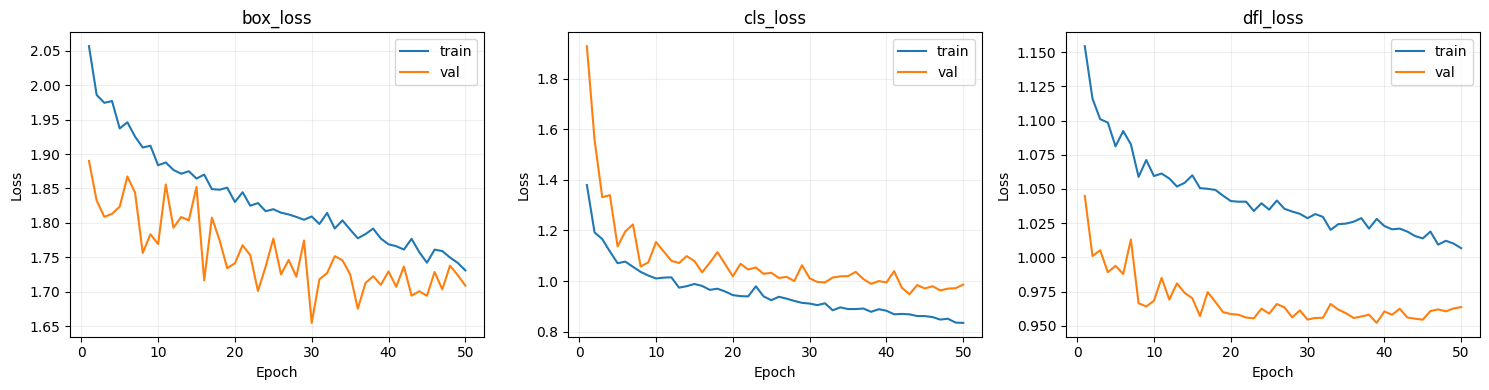

In [14]:
distance_loss = 'l1_loss' if 'train/l1_loss' in history.columns else 'dfl_loss'
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, component in zip(axes, ('box_loss','cls_loss',distance_loss)):
    for prefix in ('train','val'):
        key = f'{prefix}/{component}'
        if key in history: ax.plot(history['epoch'], history[key], label=prefix)
    ax.set(title=component, xlabel='Epoch', ylabel='Loss'); ax.grid(alpha=.2)
    if ax.lines: ax.legend()
fig.tight_layout(); fig.savefig(RUN_DIR / 'learning_curves.png', dpi=160); plt.show()


## 14. Precision–Recall Curves


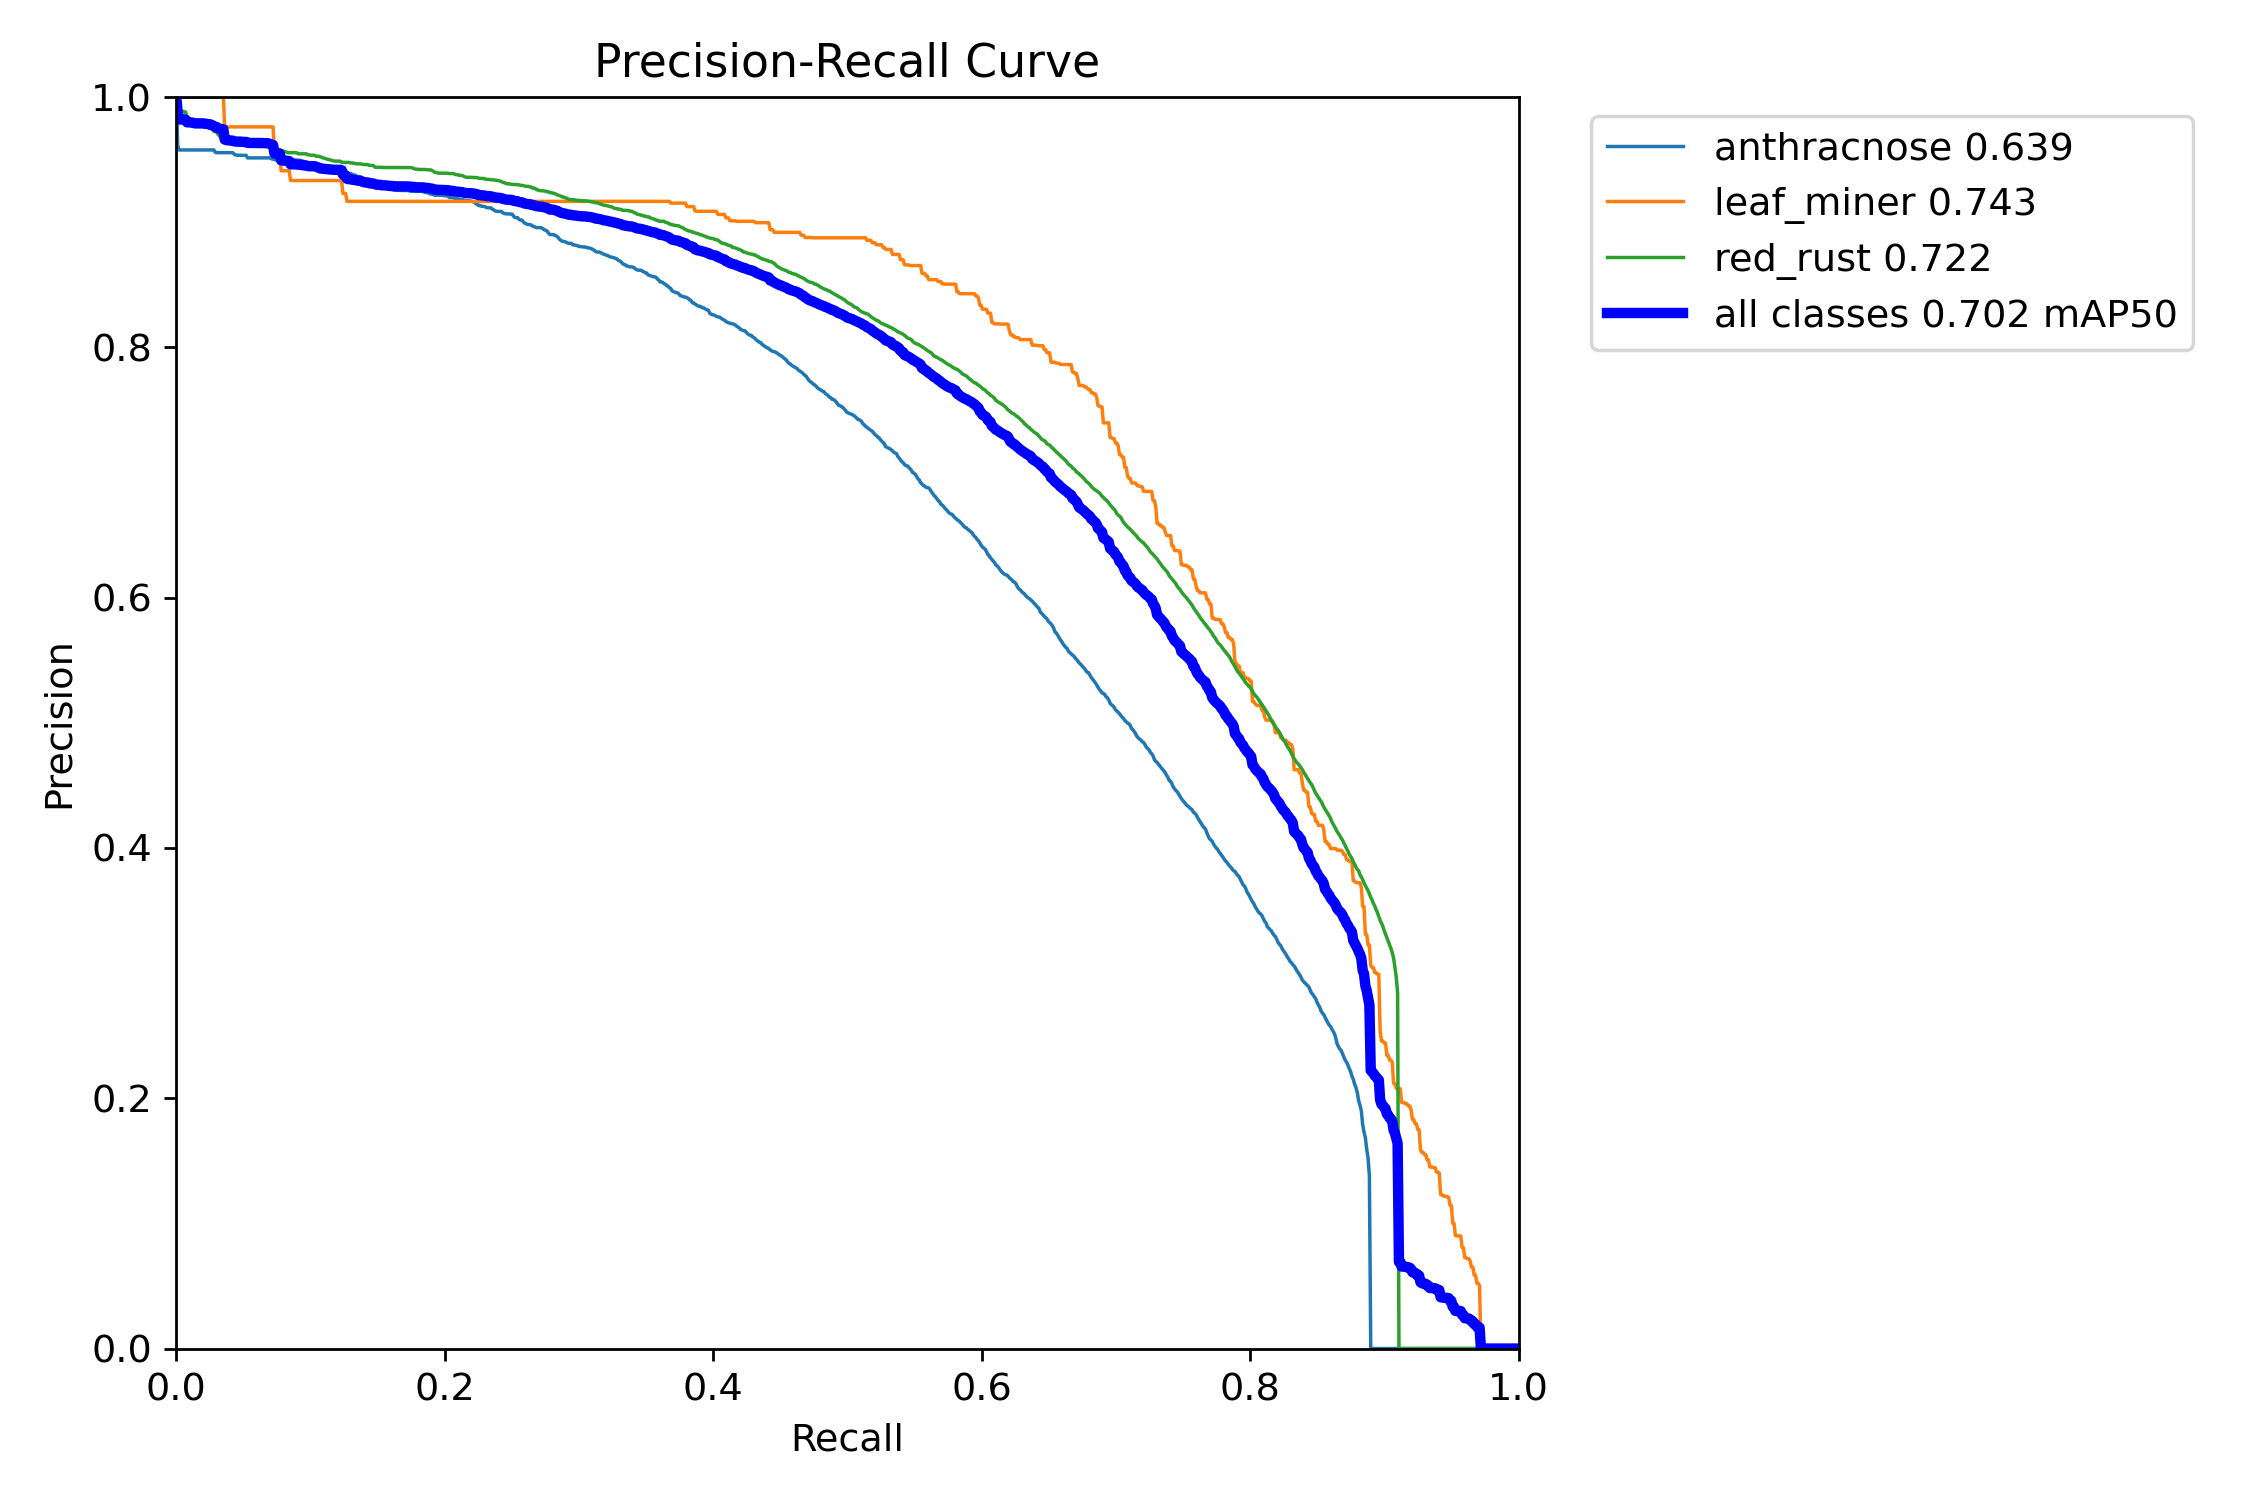

In [15]:
def require_plot(name):
    p = VALIDATION_RUN / name
    if not p.is_file(): raise FileNotFoundError(f'Thiếu plot Ultralytics: {p}')
    display(Image.open(p))
    shutil.copy2(p, RUN_DIR / name)
require_plot('BoxPR_curve.png')


## 15. F1–Confidence, Precision–Confidence, Recall–Confidence


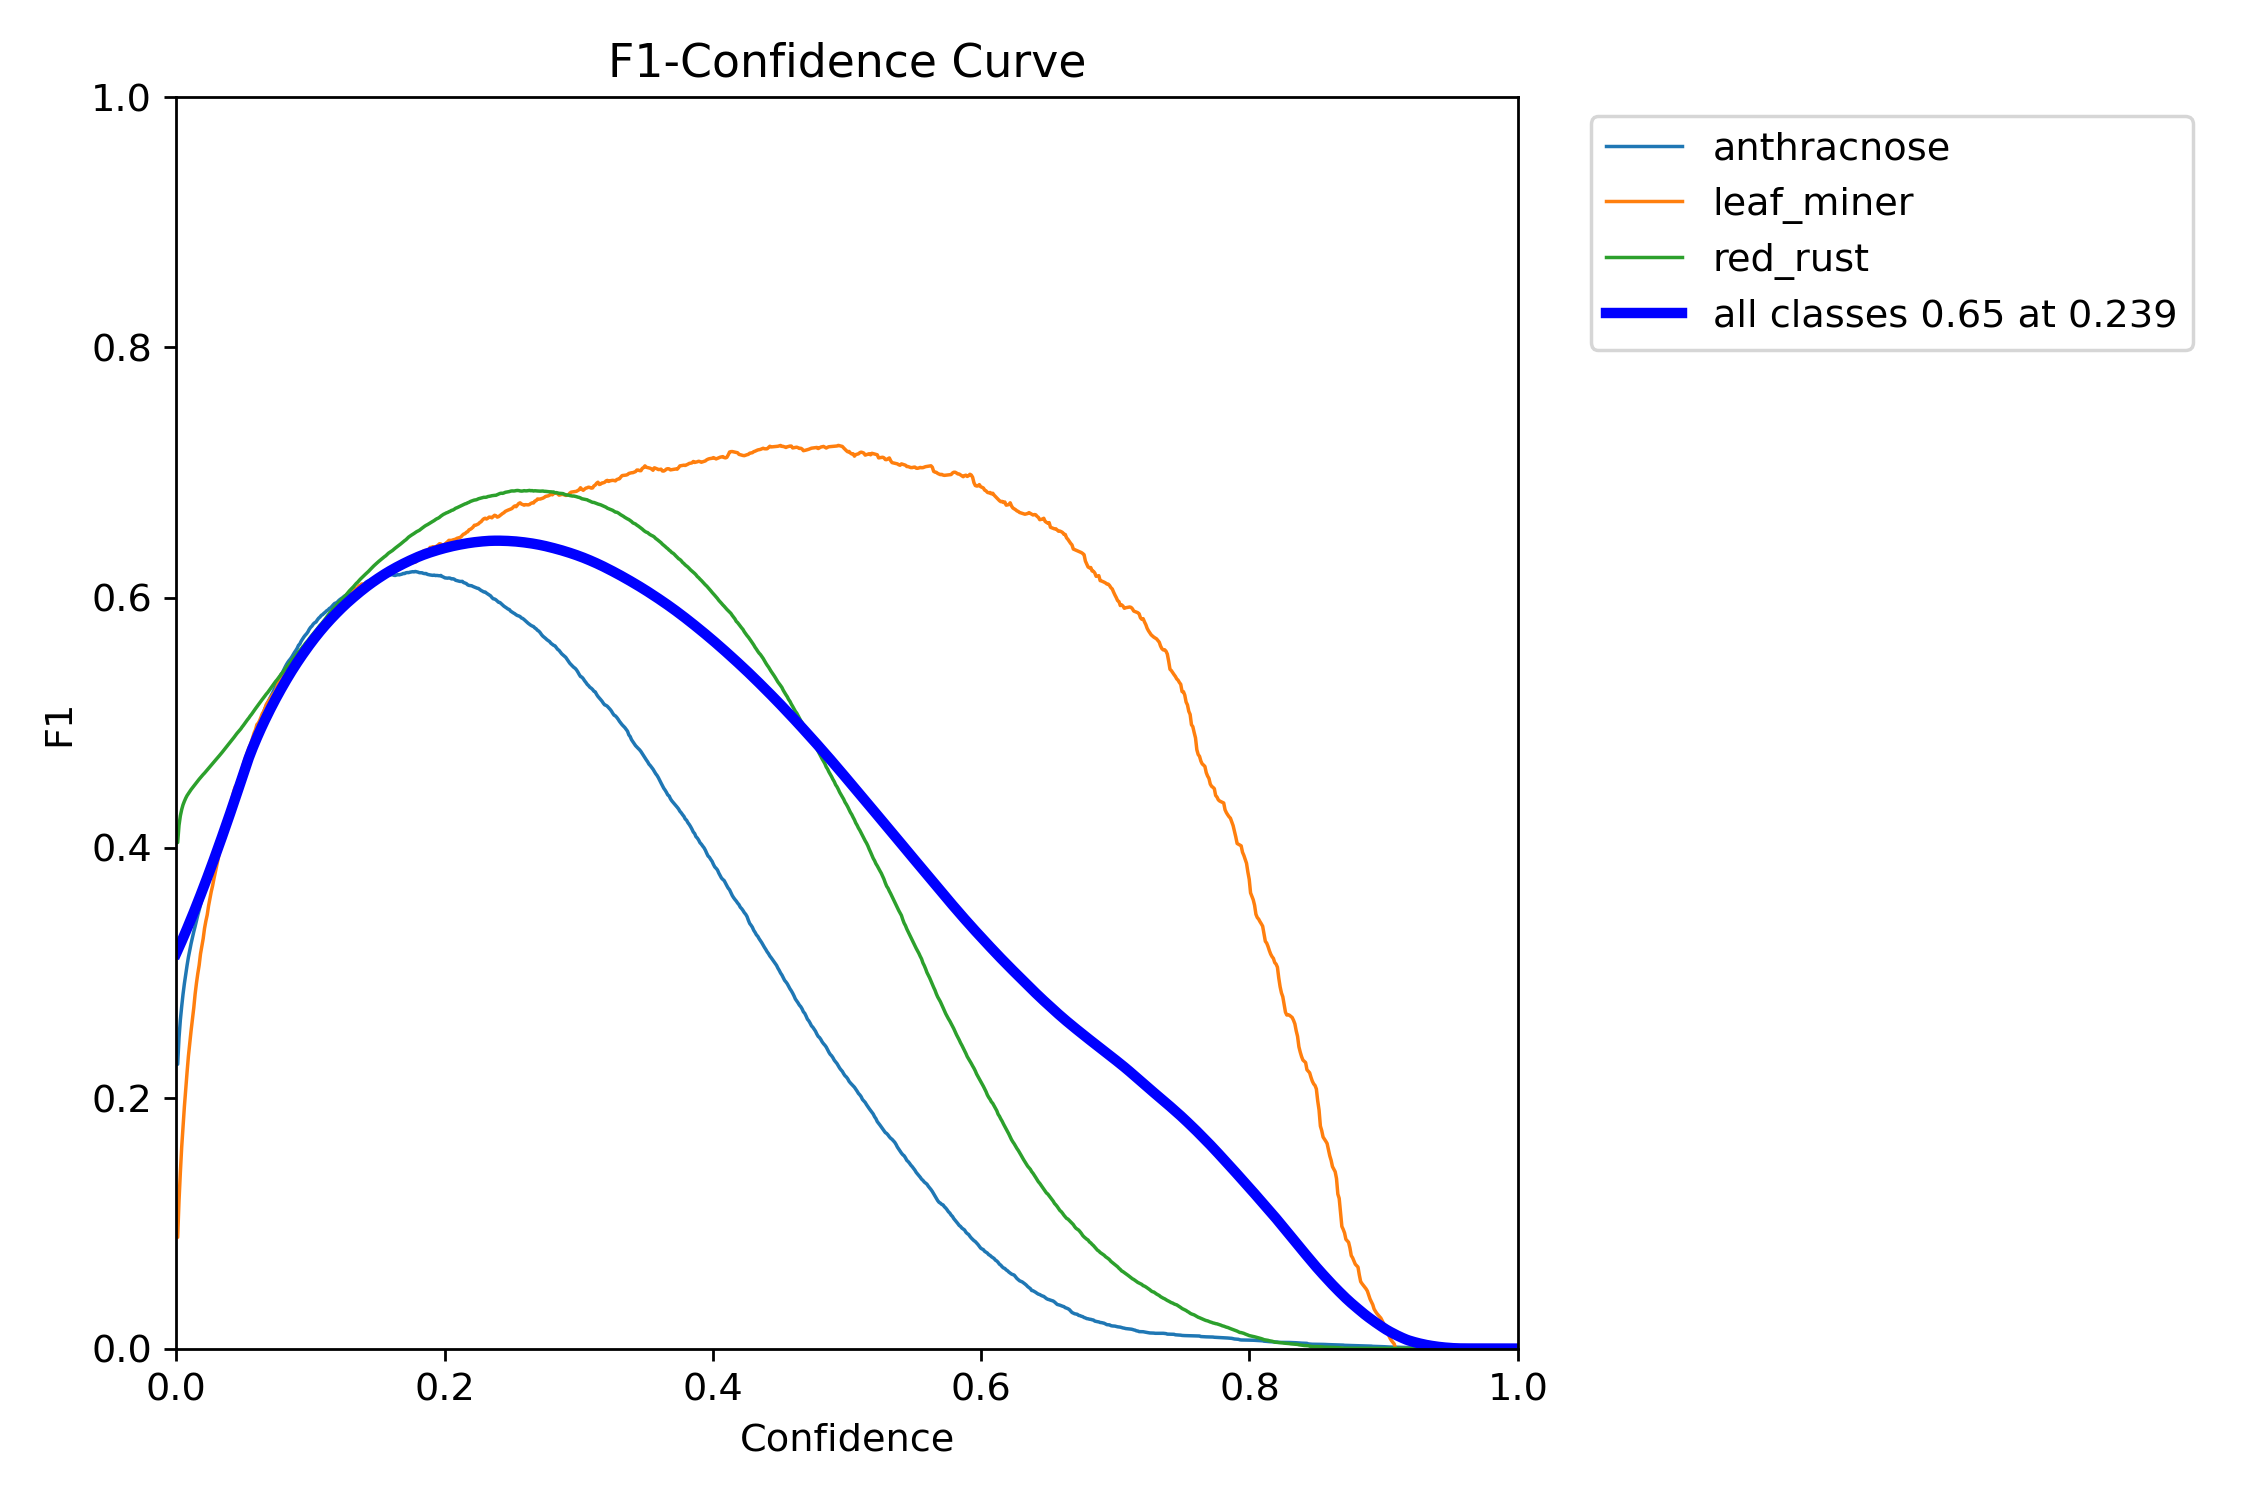

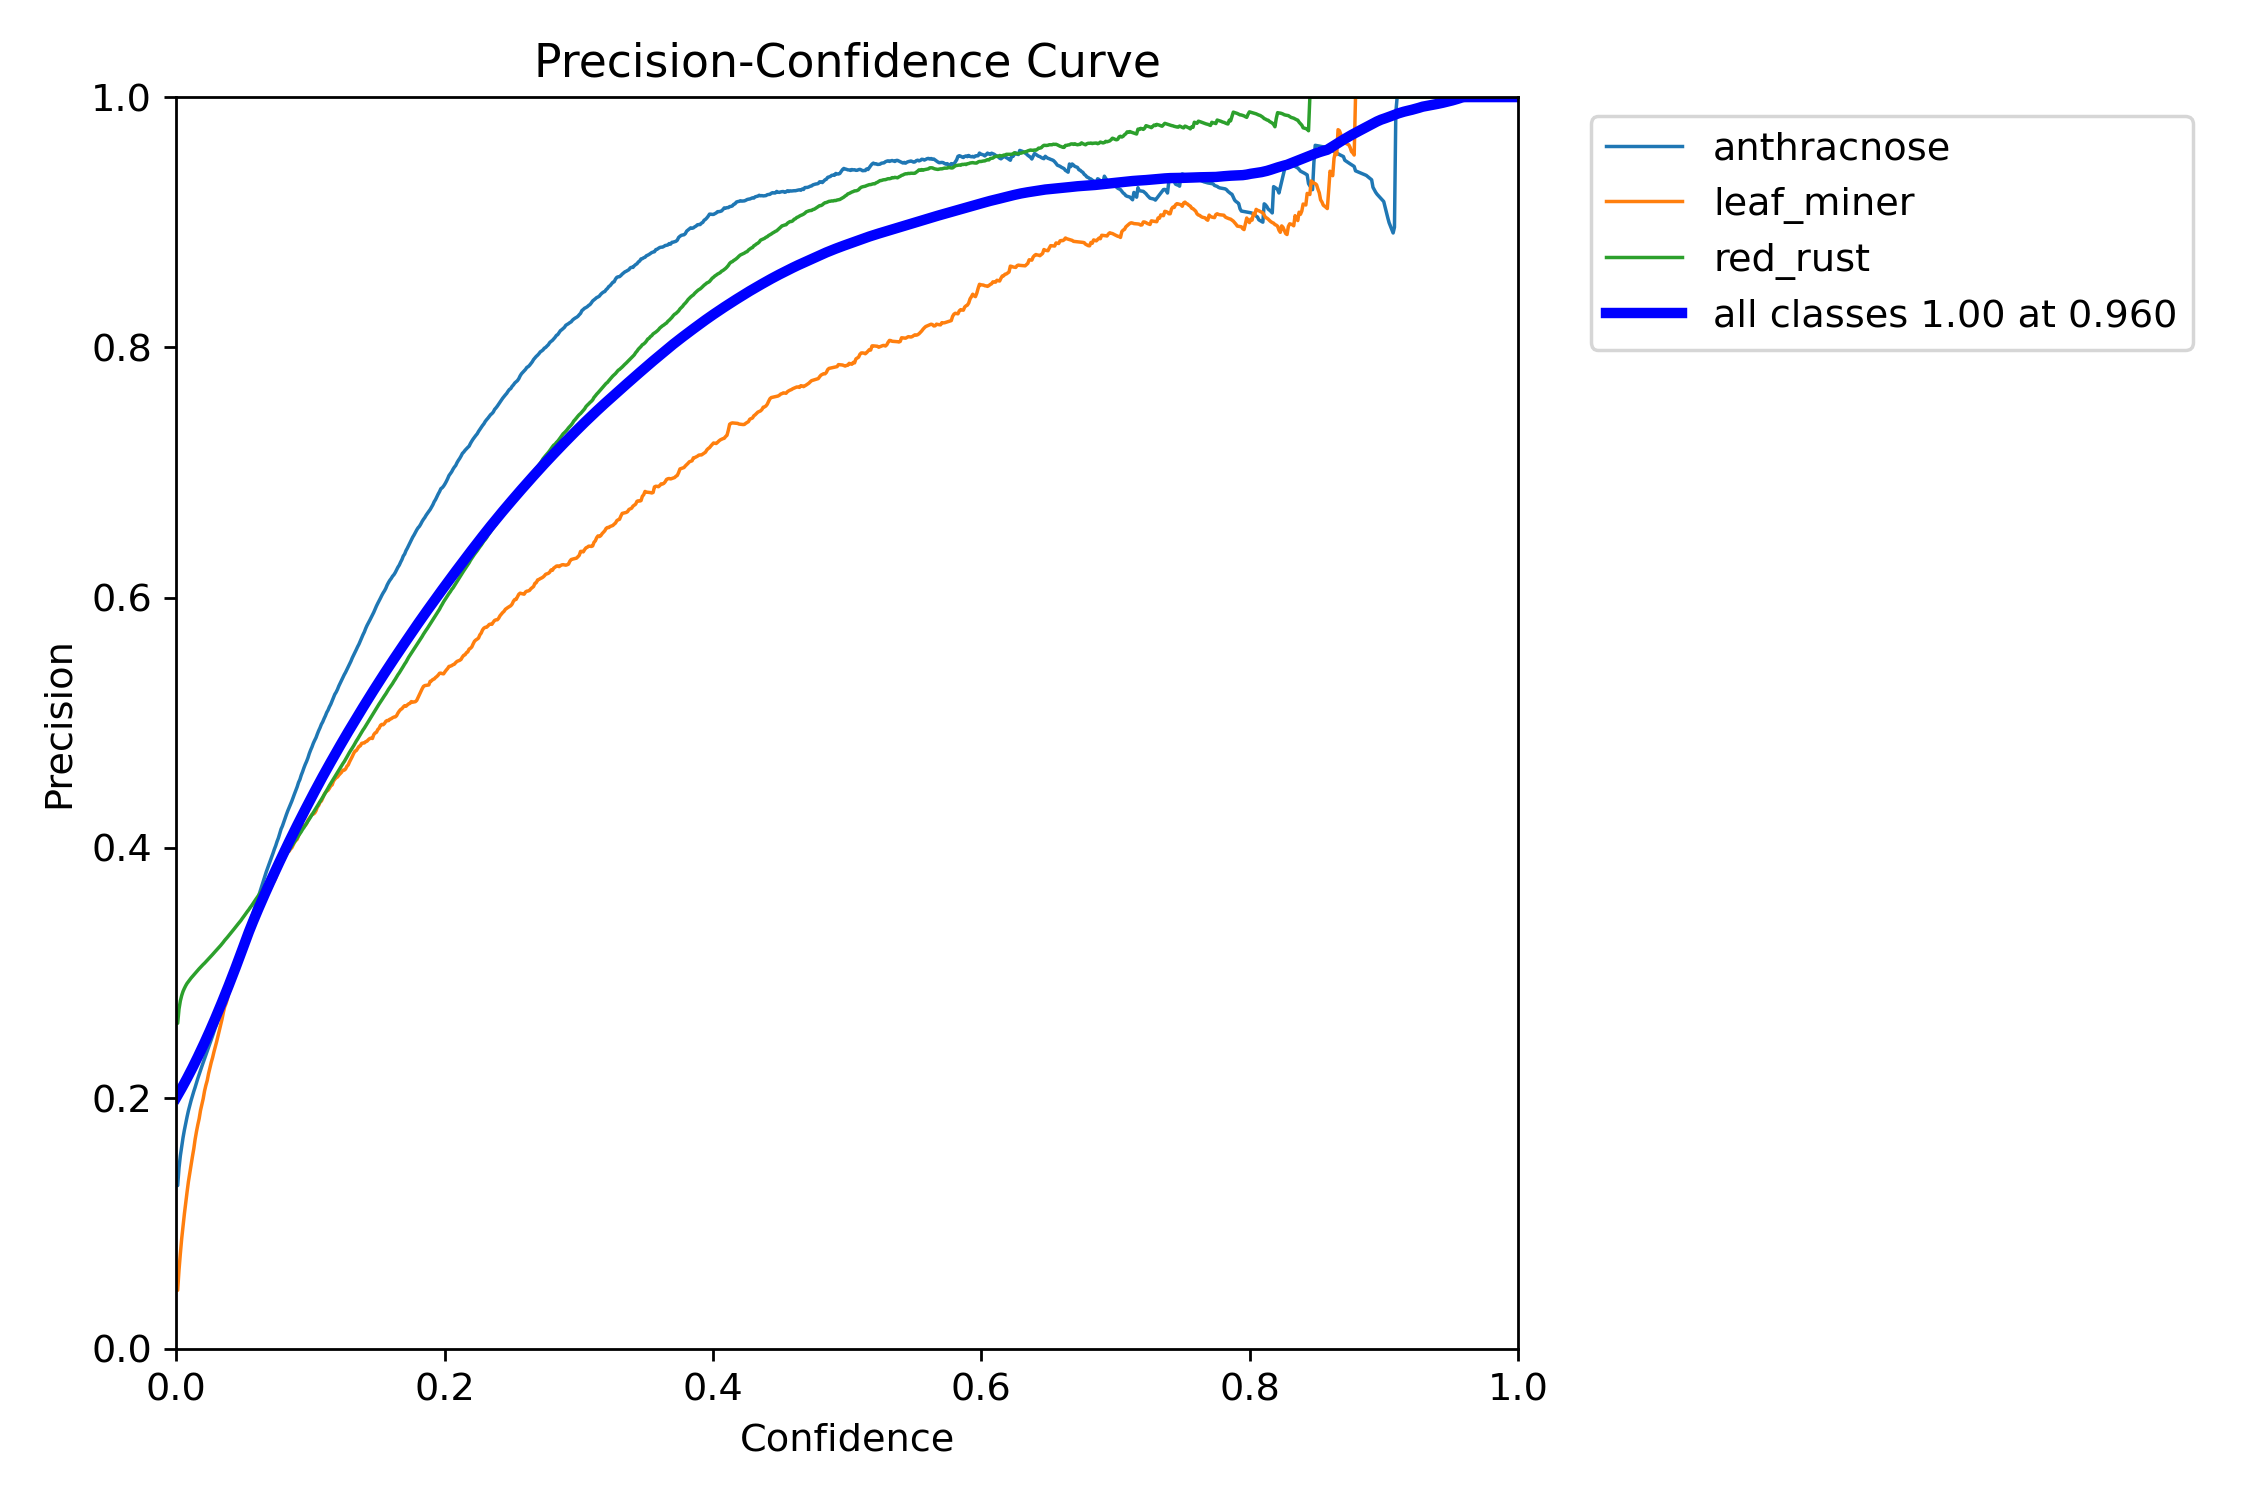

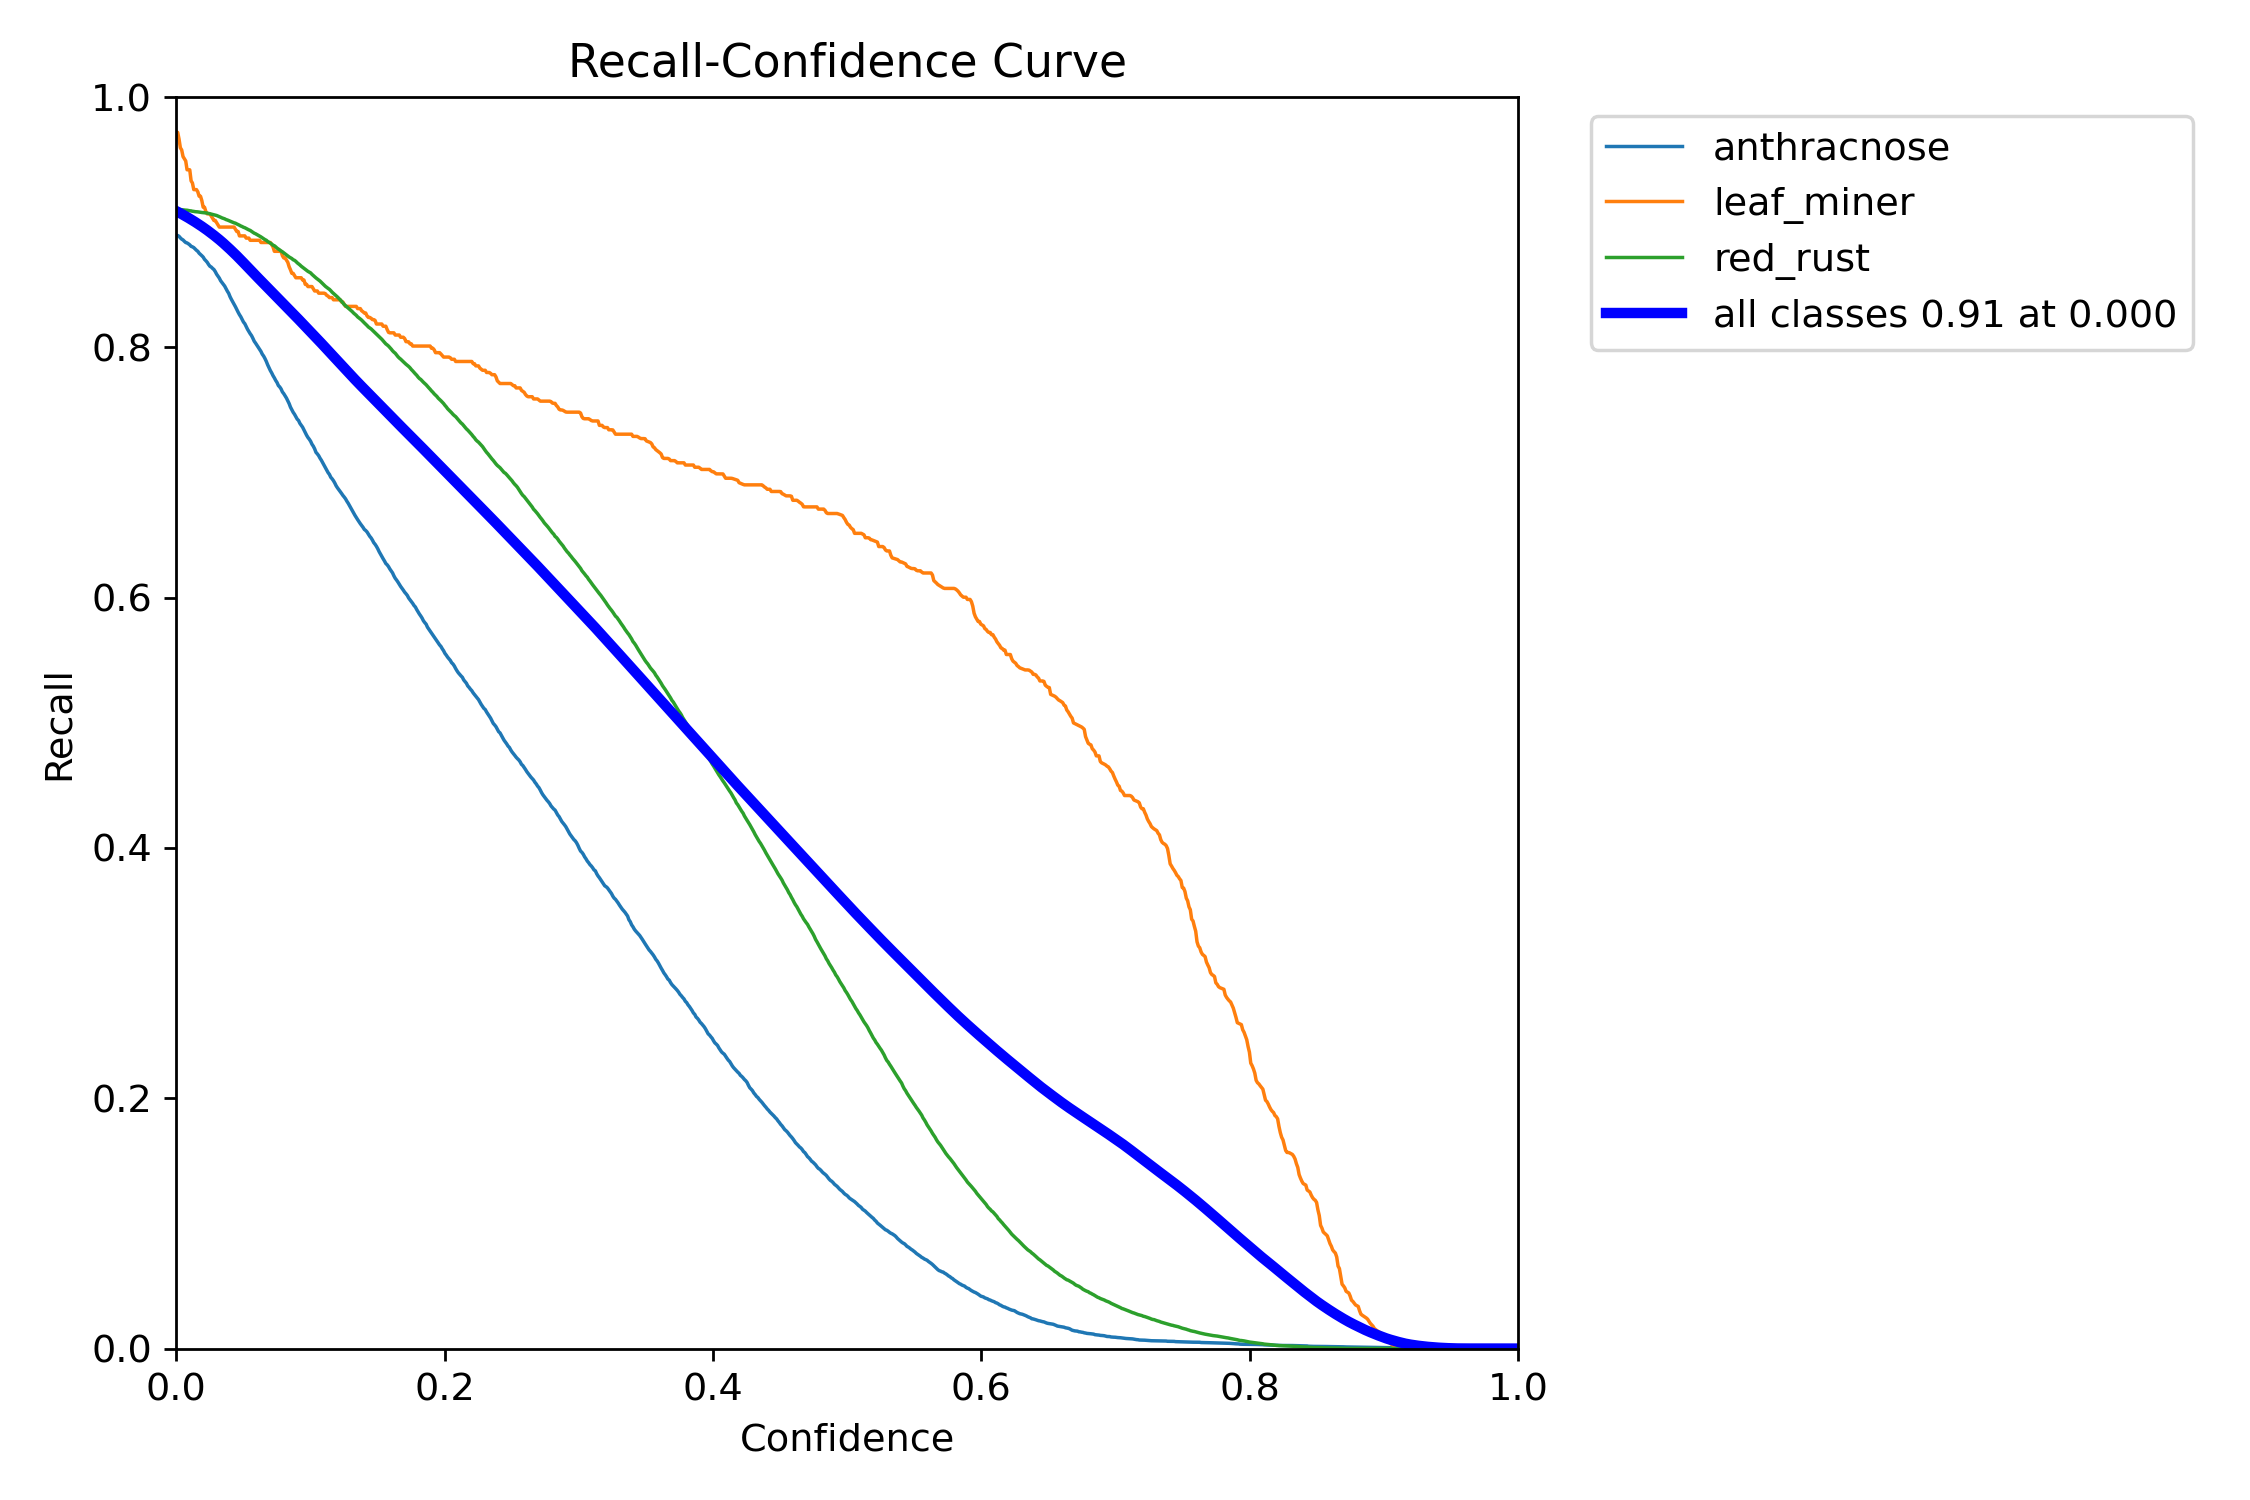

In [16]:
for plot_name in ('BoxF1_curve.png','BoxP_curve.png','BoxR_curve.png'):
    require_plot(plot_name)


## 16. Confusion Matrix


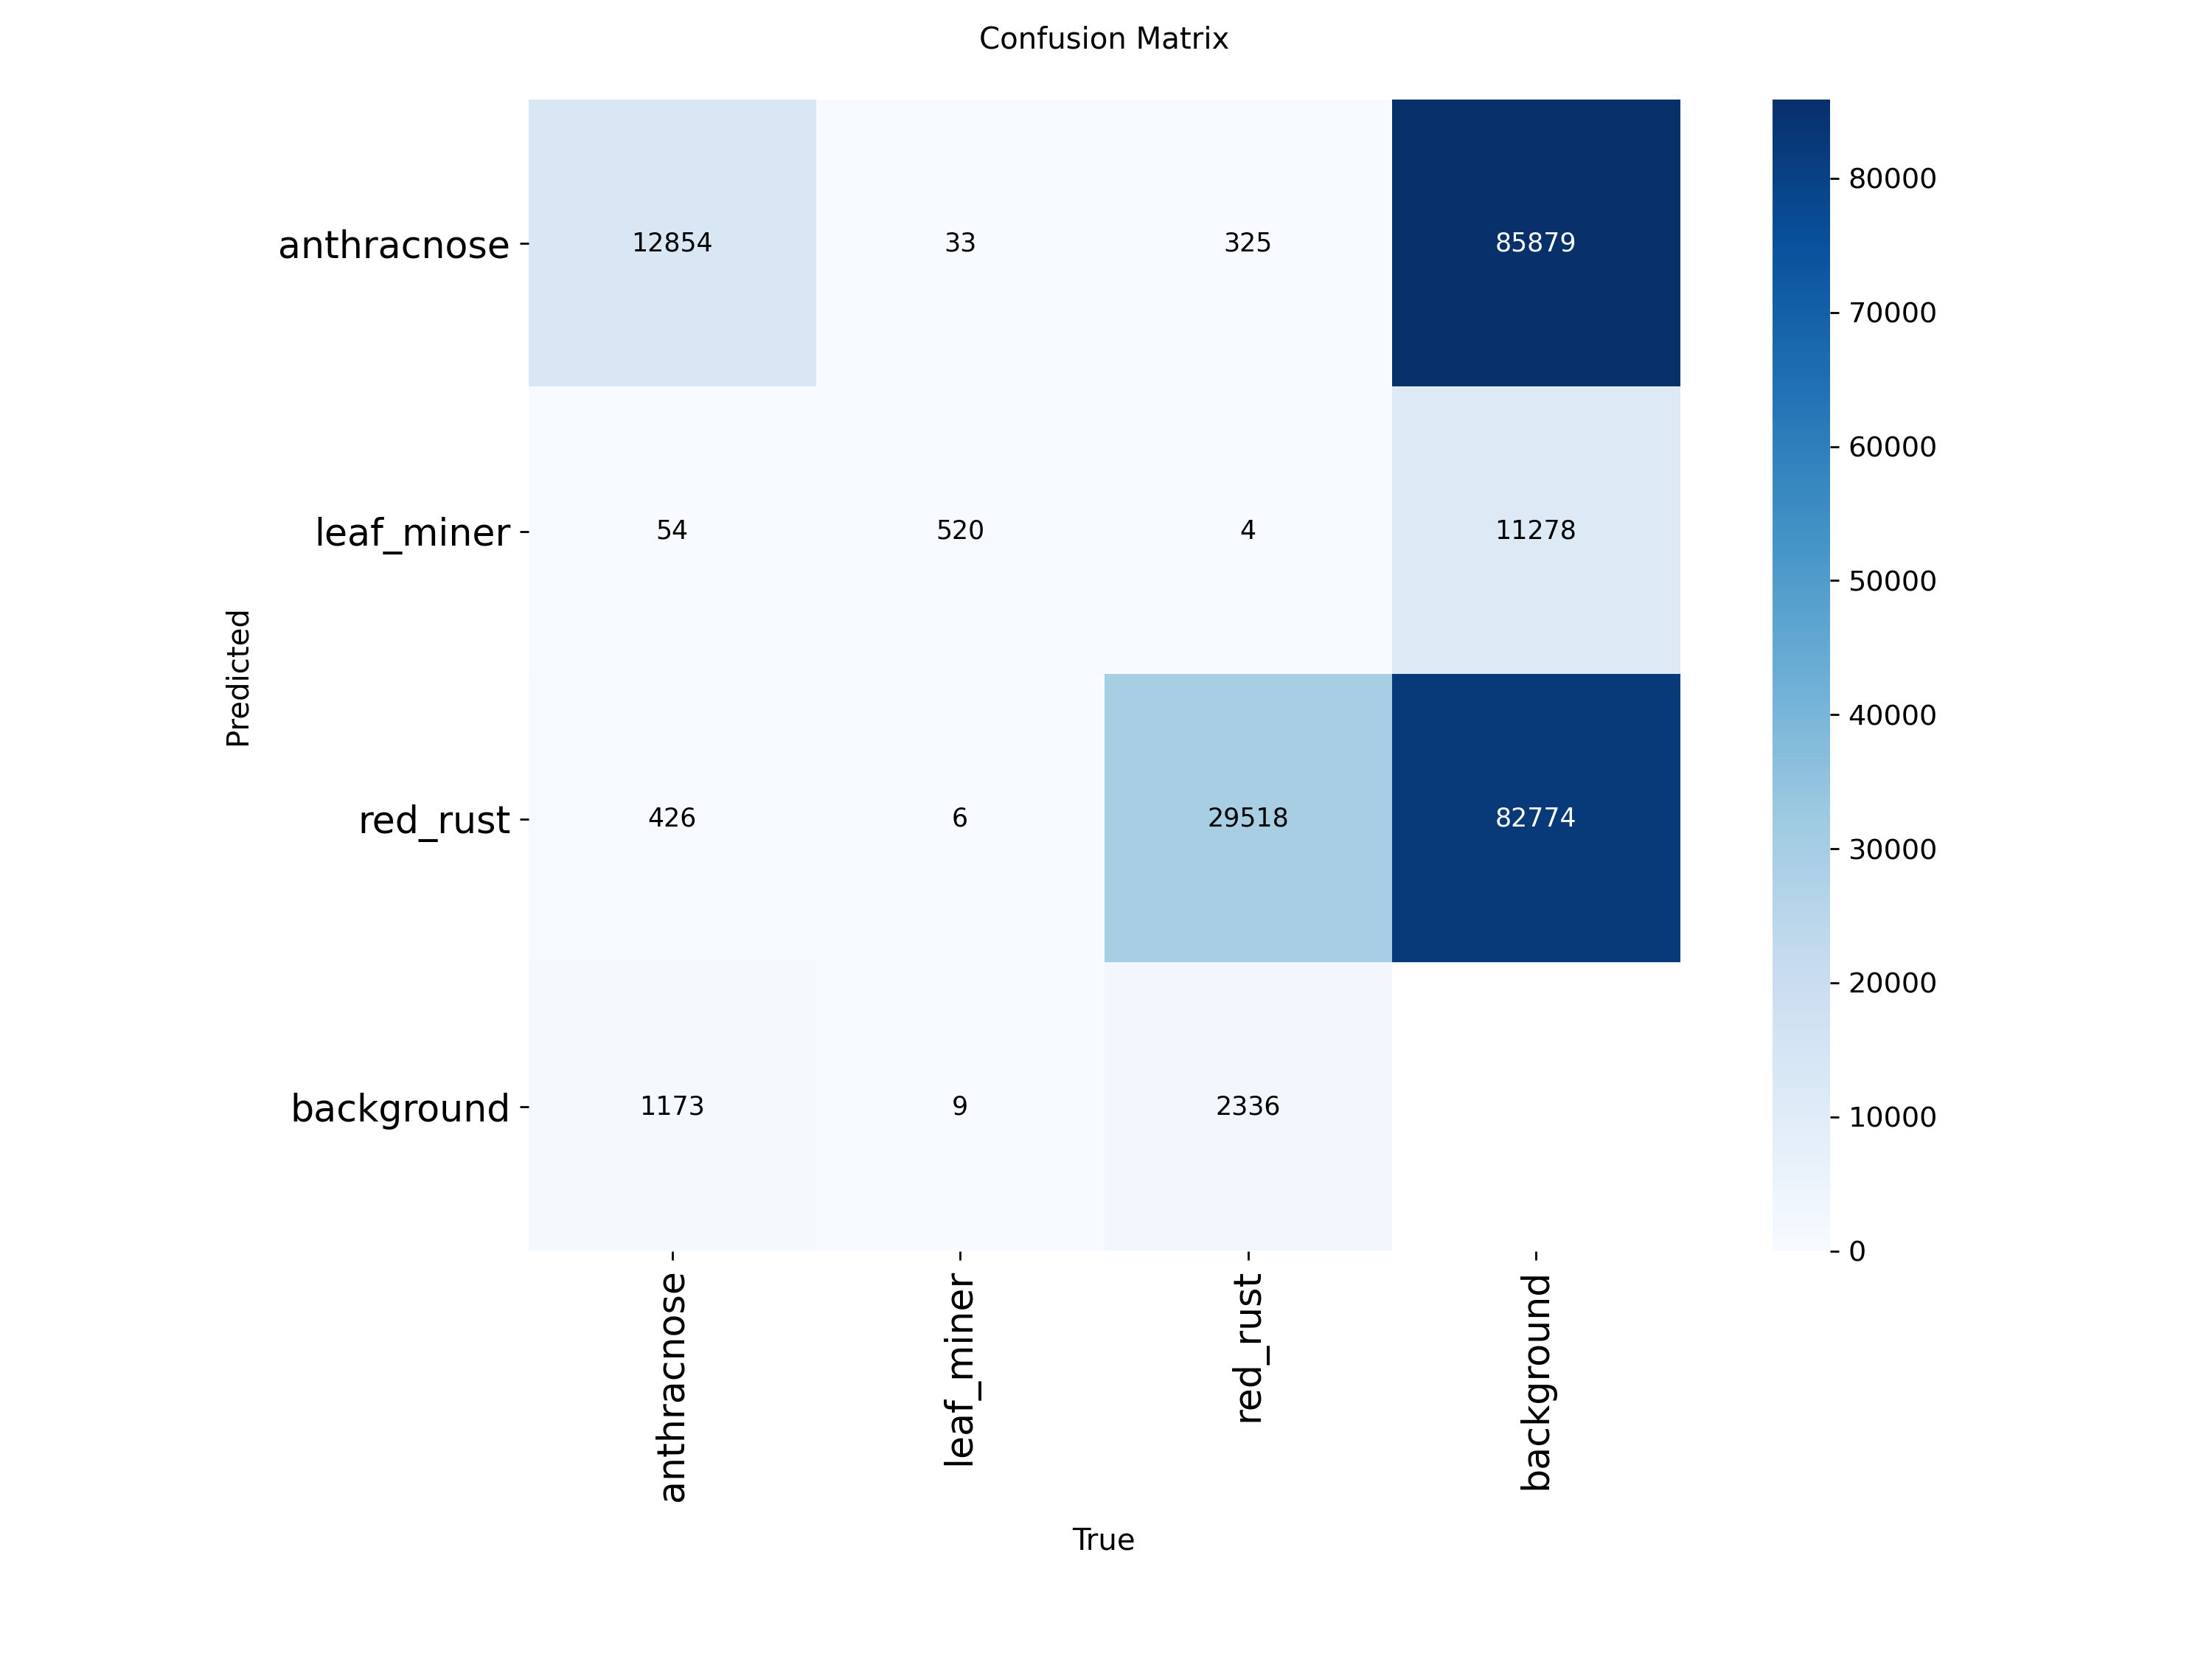

[[      12854          33         325       85879]
 [         54         520           4       11278]
 [        426           6       29518       82774]
 [       1173           9        2336           0]]


In [17]:
require_plot('confusion_matrix.png')
cm = getattr(getattr(val_metrics,'confusion_matrix',None), 'matrix', None)
if cm is not None:
    np.savetxt(RUN_DIR / 'confusion_matrix.csv', cm, delimiter=',', fmt='%d')
    print(cm)


## 17. Leaf Miner Failure Analysis

Phân tích FP/FN của Leaf Miner và số dự đoán bệnh trên ảnh âm trong Validation.


In [18]:
def xywhn_to_xyxy(row, width, height):
    _, x,y,w,h = row
    return np.array([(x-w/2)*width,(y-h/2)*height,(x+w/2)*width,(y+h/2)*height], dtype=float)

def iou(a,b):
    x1,y1 = np.maximum(a[:2], b[:2]); x2,y2 = np.minimum(a[2:], b[2:])
    intersection = max(0,x2-x1)*max(0,y2-y1)
    aa = max(0,a[2]-a[0])*max(0,a[3]-a[1]); bb = max(0,b[2]-b[0])*max(0,b[3]-b[1])
    return intersection/(aa+bb-intersection+1e-9)

def draw_example(src, gt, pred, destination):
    img = Image.open(src).convert('RGB')
    draw = ImageDraw.Draw(img)
    colors = ['#d77b27','#d62d32','#1f78b4']
    for c,box in gt:
        draw.rectangle(tuple(box), outline=colors[c], width=3)
        draw.text(tuple(box[:2]), 'GT '+CLASS_NAMES[c], fill=colors[c])
    for c,conf,box in pred:
        draw.rectangle(tuple(box), outline='#00cc66', width=2)
        draw.text(tuple(box[:2]), f'P {CLASS_NAMES[c]} {conf:.2f}', fill='#00aa55')
    img.save(destination)

failure_rows, samples = [], []
PREDICTIONS_DIR = RUN_DIR / 'validation_predictions'; PREDICTIONS_DIR.mkdir(exist_ok=True)
im_dir, lab_dir = SPLITS['val']
for idx, im in enumerate(SPLIT_IMAGES['val']):
    gt_labels = read_labels(label_for(im, im_dir, lab_dir))
    with Image.open(im) as source: width,height = source.size
    gt = [(r[0], xywhn_to_xyxy(r,width,height)) for r in gt_labels]
    prediction = best_model.predict(source=str(im), imgsz=IMGSZ, conf=PRED_CONF,
                                    device=DEVICE, verbose=False)[0]
    pred = [(int(c),float(score),box) for c,score,box in zip(
        prediction.boxes.cls.cpu().numpy(), prediction.boxes.conf.cpu().numpy(),
        prediction.boxes.xyxy.cpu().numpy())]
    pred.sort(key=lambda x: -x[1]); matched = set(); fp=fn=shifted=low=tp=0
    for c,score,box in pred:
        if c != 1: continue
        eligible = [(j,iou(box,gbox)) for j,(gc,gbox) in enumerate(gt) if gc==1 and j not in matched]
        best_j,best_iou = max(eligible,key=lambda z:z[1]) if eligible else (None,0.)
        if best_iou >= MATCH_IOU:
            matched.add(best_j); tp += 1; low += score < LOW_CONF
        else:
            fp += 1; shifted += 0.1 <= best_iou < MATCH_IOU
    fn = sum(c==1 and j not in matched for j,(c,_) in enumerate(gt))
    multi = len(set(c for c,_ in gt)) > 1
    row = {'image':str(im.relative_to(im_dir)), 'leaf_miner_tp':tp,'leaf_miner_fp':fp,
           'leaf_miner_fn':fn,'shifted_boxes_candidate':shifted,'low_confidence_tp':low,
           'multi_disease_gt':bool(multi)}
    failure_rows.append(row)
    score = 10*(fp+fn)+5*shifted+3*low+2*multi
    samples.append((score, idx, im, gt, pred))
    if (idx+1)%100==0: print('Analysed',idx+1,'/',len(SPLIT_IMAGES['val']))
failures = pd.DataFrame(failure_rows)
failures.to_csv(RUN_DIR / 'leaf_miner_failure_analysis.csv',index=False)
error_samples = sorted((s for s in samples if s[0]>0),key=lambda z:(-z[0],z[1]))[:15]
correct_samples = [s for s in samples if s[0]==0][:5]
chosen = error_samples + correct_samples
if len(chosen)<20:
    used = {s[1] for s in chosen}
    chosen += [s for s in samples if s[1] not in used][:20-len(chosen)]
for _,idx,im,gt,pred in chosen:
    draw_example(im,gt,pred,PREDICTIONS_DIR / f'{idx:04d}_{im.stem}.jpg')
FAILURE_SUMMARY = {k:int(failures[k].sum()) for k in
                   ('leaf_miner_tp','leaf_miner_fp','leaf_miner_fn','shifted_boxes_candidate',
                    'low_confidence_tp','multi_disease_gt')}
save_json(RUN_DIR / 'leaf_miner_failure_summary.json',FAILURE_SUMMARY)
print(FAILURE_SUMMARY)


Analysed 100 / 951
Analysed 200 / 951
Analysed 300 / 951
Analysed 400 / 951
Analysed 500 / 951
Analysed 600 / 951
Analysed 700 / 951
Analysed 800 / 951
Analysed 900 / 951
{'leaf_miner_tp': 495, 'leaf_miner_fp': 1026, 'leaf_miner_fn': 73, 'shifted_boxes_candidate': 172, 'low_confidence_tp': 66, 'multi_disease_gt': 503}


## 18. Experiment Summary và baseline NEG_V03

Chỉ kết luận tác dụng class weighting khi có run `cls_pw=0` cùng NEG_V03, cùng model, split, seed và recipe.


In [19]:
comparison_text = 'Chưa có baseline cls_pw=0 trên cùng NEG_V03.'
if BASELINE_METRICS:
    baseline_path = Path(BASELINE_METRICS)
    if baseline_path.suffix.lower() == '.zip':
        with zipfile.ZipFile(baseline_path) as archive:
            baseline = json.loads(archive.read('metrics.json').decode('utf-8'))
    else:
        baseline = json.loads(baseline_path.read_text(encoding='utf-8'))
    if baseline.get('model') != MODEL_WEIGHTS or baseline.get('split') != 'val' or baseline.get('cls_pw') != 0:
        raise ValueError('Baseline phải cùng model, split=val, cls_pw=0')
    for key in ('dataset_fingerprint', 'training_recipe'):
        if baseline.get(key) != METRICS.get(key):
            raise ValueError(f'Baseline khác {key}')
    if baseline.get('ultralytics_version') != METRICS.get('ultralytics_version'):
        raise ValueError('Baseline khác Ultralytics version')
    b = {r['class']: r for r in baseline['per_class']}
    if set(b) != set(CLASS_NAMES): raise ValueError('Baseline thiếu class')
    effect_rows = [{'class': name, **{f'delta_{key}': float(rows[i][key])-float(b[name][key])
                       for key in ('precision', 'recall', 'ap50', 'ap50_95')}}
                   for i, name in enumerate(CLASS_NAMES)]
    pd.DataFrame(effect_rows).to_csv(RUN_DIR/'class_weight_effect.csv', index=False)
    save_json(RUN_DIR/'class_weight_effect.json',
              {'direction': 'weighted minus unweighted', 'per_class': effect_rows})
    comparison_text = 'Đã tính chênh lệch weighted − unweighted; xem class_weight_effect.csv.'
summary = {'experiment_id': EXPERIMENT_ID, 'validation_map50': METRICS['map50'],
           'validation_map50_95': METRICS['map50_95'], 'leaf_miner': rows[1],
           'training_seconds': TRAIN_SECONDS, 'failure_summary': FAILURE_SUMMARY,
           'class_weight_effect': comparison_text}
save_json(RUN_DIR/'experiment_summary.json', summary)
README = f"""# {EXPERIMENT_ID}

Dataset: {DATASET_STATS['source_archive'] or 'thư mục cấu hình'}; Train/Val/Test = {len(SPLIT_IMAGES['train'])}/{len(SPLIT_IMAGES['val'])}/{len(SPLIT_IMAGES['test'])}.
Classes: {CLASS_NAMES}. Healthy và not_cashew_leaf là ảnh âm 0 box.
Model: {MODEL_WEIGHTS}, seed {SEED}, cls_pw={CLS_PW}. Trọng số: {CLASS_WEIGHTS['effective']}.
Validation mAP50={METRICS['map50']:.4f}, mAP50-95={METRICS['map50_95']:.4f}.
Leaf Miner: {rows[1]}.
Preflight: metadata/negative_image_preflight.json.
So sánh baseline: {comparison_text}
"""
(RUN_DIR/'README.md').write_text(README, encoding='utf-8')
print(README)


# EXP-Y8S-NEG-V03-001-CLASS-WEIGHTED

Dataset: /content/exp_yolo_neg_v03_weighted/CASHEW_YOLO_MASTER_FINAL_NEG_V03 (2).zip; Train/Val/Test = 3497/951/412.
Classes: ['anthracnose', 'leaf_miner', 'red_rust']. Healthy và not_cashew_leaf là ảnh âm 0 box.
Model: yolov8s.pt, seed 42, cls_pw=0.25. Trọng số: {'anthracnose': 0.7780247926712036, 'leaf_miner': 1.5752495527267456, 'red_rust': 0.6467254757881165}.
Validation mAP50=0.7015, mAP50-95=0.3800.
Leaf Miner: {'class_id': 1, 'class': 'leaf_miner', 'precision': 0.5823499103698184, 'recall': 0.7732748349889701, 'ap50': 0.7432024044682879, 'ap50_95': 0.4756390423005358, 'train_boxes': 2076, 'class_weight': 1.5752495527267456}.
Preflight: metadata/negative_image_preflight.json.
So sánh baseline: Chưa có baseline cls_pw=0 trên cùng NEG_V03.



## 19. So sánh YOLOv8s và YOLO26s (khi đã có cả hai run)

Hai notebook ghi cùng schema `metrics.json`. Cell này tự tìm run của model còn lại trong `OUTPUT_ROOT`, hoặc dùng `OTHER_MODEL_METRICS`. Chỉ xuất bảng nếu dataset fingerprint, `cls_pw` và training recipe trùng nhau.


In [20]:
other_tag = 'Y8S' if MODEL_TAG == 'Y26S' else 'Y26S'
other_path = (Path(OTHER_MODEL_METRICS) if OTHER_MODEL_METRICS else
              OUTPUT_ROOT / EXPERIMENT_ID.replace(f'EXP-{MODEL_TAG}',f'EXP-{other_tag}',1) / 'metrics.json')
if other_path.is_file():
    other = json.loads(other_path.read_text(encoding='utf-8'))
    for key in ('dataset_fingerprint','cls_pw','training_recipe','split'):
        if other.get(key) != METRICS.get(key):
            raise ValueError(f'Không thể so sánh hai model: {key} khác nhau.')
    comparison_rows = []
    for result in (METRICS,other):
        for class_result in result['per_class']:
            comparison_rows.append({'model':result['model'], **{k:class_result[k]
                for k in ('class','precision','recall','ap50','ap50_95')}})
    model_comparison = pd.DataFrame(comparison_rows)
    model_comparison.to_csv(RUN_DIR/'model_comparison.csv',index=False)
    save_json(RUN_DIR/'model_comparison.json',
        {'models':[{'model':m['model'],'map50':m['map50'],'map50_95':m['map50_95']}
                   for m in (METRICS,other)],'per_class':comparison_rows})
    display(model_comparison)
    print('mAP50 / mAP50-95:', [(m['model'],m['map50'],m['map50_95']) for m in (METRICS,other)])
    with (RUN_DIR/'README.md').open('a',encoding='utf-8') as f:
        f.write('\nSo sánh YOLOv8s/YOLO26s: xem model_comparison.csv và model_comparison.json. '
                'Một seed cho mỗi model; chênh lệch chưa chứng minh tính ổn định.\n')
else:
    print('Chưa có metrics của model còn lại:',other_path)
    print('Sau khi chạy notebook còn lại, chạy lại cell này và các cell export/upload.')


Chưa có metrics của model còn lại: /content/exp_yolo_neg_v03_weighted/EXP-Y26S-NEG-V03-001-CLASS-WEIGHTED/metrics.json
Sau khi chạy notebook còn lại, chạy lại cell này và các cell export/upload.


## 20. Export FULL & ANALYSIS ZIP

FULL chứa checkpoint, log, notebook và toàn bộ output thí nghiệm, nhưng không chứa dataset. Notebook mang sẵn bản nguồn để đóng gói, không phụ thuộc Colab browser/widget. Nếu chạy từ một bản notebook cũ không có nguồn nhúng, cell tạo bản phục hồi từ code đã thực thi và ghi rõ nguồn gốc. ANALYSIS chỉ chứa số liệu, biểu đồ và mẫu dự đoán; không chứa `.pt`.


In [21]:
notebook_name = f'EXP-{MODEL_TAG}-NEG-V03-001_CLASS_WEIGHTED.ipynb'
notebook_copy = RUN_DIR / notebook_name
notebook_source = Path(NOTEBOOK_SOURCE).expanduser() if NOTEBOOK_SOURCE else None
EMBEDDED_NOTEBOOK_B64 = '...'
source_origin = None
if notebook_source is not None and notebook_source.is_file():
    shutil.copy2(notebook_source,notebook_copy)
    source_origin = 'configured_file'
elif EMBEDDED_NOTEBOOK_B64 != '__EMBEDDED_NOTEBOOK_B64__':
    import base64, zlib
    notebook_copy.write_bytes(zlib.decompress(base64.b64decode(EMBEDDED_NOTEBOOK_B64)))
    source_origin = 'embedded_canonical_source'
elif notebook_copy.is_file():
    source_origin = 'existing_run_copy'
else:
    candidates = [p for p in Path.cwd().rglob(notebook_name) if p.resolve()!=notebook_copy.resolve()]
    if len(candidates)==1:
        shutil.copy2(candidates[0],notebook_copy)
        source_origin = 'runtime_file'
    else:
        shell = get_ipython()
        executed = [source for _,_,source in shell.history_manager.get_range(output=False)
                    if source.strip()]
        if not executed: raise RuntimeError('Không có code history để phục hồi notebook.')
        recovered = {'cells':[{'cell_type':'markdown','metadata':{},'source':
                     'Bản phục hồi từ code history; Markdown gốc có thể thiếu.\n'}] +
                     [{'cell_type':'code','execution_count':None,'metadata':{},'outputs':[],
                       'source':source} for source in executed],
                     'metadata':{'kernelspec':{'display_name':'Python 3','language':'python',
                                              'name':'python3'}},'nbformat':4,'nbformat_minor':5}
        notebook_copy.write_text(json.dumps(recovered,ensure_ascii=False,indent=1),encoding='utf-8')
        source_origin = 'kernel_history_reconstruction'
if not notebook_copy.is_file() or notebook_copy.stat().st_size==0:
    raise RuntimeError('Notebook trong FULL ZIP rỗng hoặc không tồn tại')
try:
    notebook_data = json.loads(notebook_copy.read_text(encoding='utf-8'))
    if notebook_data.get('nbformat') != 4 or not notebook_data.get('cells'):
        raise ValueError('Thiếu nbformat/cells')
except Exception as exc:
    raise ValueError(f'File notebook dùng cho FULL ZIP không hợp lệ: {notebook_copy}') from exc
save_json(RUN_DIR/'source_notebook_provenance.json',
          {'source_origin':source_origin,'file':notebook_name,
           'note':'embedded_canonical_source không gồm output của phiên đang chạy; '
                  'kernel_history_reconstruction có thể thiếu Markdown gốc.'})
print('Notebook đã lưu cho FULL ZIP:',notebook_copy,'| nguồn:',source_origin)
full_zip = OUTPUT_ROOT / f'{ARCHIVE_PREFIX}_FULL.zip'
analysis_zip = OUTPUT_ROOT / f'{ARCHIVE_PREFIX}_ANALYSIS.zip'
analysis_names = {'metadata/negative_image_preflight.json','metrics.json','per_class_metrics.csv','results.csv','experiment_config.json',
                  'dataset_statistics.json','class_weights.json','README.md','learning_curves.png',
                  'BoxPR_curve.png','BoxF1_curve.png','BoxP_curve.png','BoxR_curve.png',
                  'confusion_matrix.png','confusion_matrix.csv','leaf_miner_failure_analysis.csv',
                  'leaf_miner_failure_summary.json','class_weight_effect.csv',
                  'class_weight_effect.json',
                  'model_comparison.csv','model_comparison.json'}
with zipfile.ZipFile(full_zip,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=6) as z:
    for p in RUN_DIR.rglob('*'):
        if p.is_file() and 'dataset_working_copy' not in p.parts:
            z.write(p,p.relative_to(RUN_DIR))
with zipfile.ZipFile(analysis_zip,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=6) as z:
    for p in RUN_DIR.rglob('*'):
        if p.is_file() and str(p.relative_to(RUN_DIR)).replace('\\','/') in analysis_names:
            z.write(p,p.relative_to(RUN_DIR))
    for p in sorted(PREDICTIONS_DIR.glob('*.jpg'))[:20]: z.write(p,Path('validation_predictions')/p.name)
for archive in (full_zip,analysis_zip):
    with zipfile.ZipFile(archive) as z:
        if z.testzip() is not None: raise RuntimeError(f'ZIP hỏng: {archive}')
    print(archive,archive.stat().st_size/1024**2,'MiB')
if analysis_zip.stat().st_size > 25*1024**2:
    warnings.warn('ANALYSIS ZIP lớn hơn 25 MB; cân nhắc giảm ảnh mẫu trước khi upload.')


Notebook đã lưu cho FULL ZIP: /content/exp_yolo_neg_v03_weighted/EXP-Y8S-NEG-V03-001-CLASS-WEIGHTED/EXP-Y8S-NEG-V03-001_CLASS_WEIGHTED.ipynb | nguồn: embedded_canonical_source
/content/exp_yolo_neg_v03_weighted/EXP-Y8S-NEG-V03-001_FULL.zip 53.30901336669922 MiB
/content/exp_yolo_neg_v03_weighted/EXP-Y8S-NEG-V03-001_ANALYSIS.zip 2.010763168334961 MiB


## 21. Upload cả hai ZIP lên Google Drive

Dùng tài khoản đang đăng nhập Colab hoặc Application Default Credentials có quyền ghi Drive. Với Kaggle, cấp credentials qua môi trường/secrets rồi chạy; không đưa token vào notebook. Nếu không xác thực hoặc upload lỗi, giữ ZIP tại output và ghi rõ lỗi.


In [22]:
DRIVE_UPLOADS = {}
if UPLOAD_TO_DRIVE:
    try:
        for package,module in [('google-auth','google.auth'),
                               ('google-api-python-client','googleapiclient')]:
            try: importlib.util.find_spec(module)
            except ModuleNotFoundError: subprocess.check_call([sys.executable,'-m','pip','install',package])
            else:
                if importlib.util.find_spec(module) is None:
                    subprocess.check_call([sys.executable,'-m','pip','install',package])
        import google.auth
        from googleapiclient.discovery import build
        from googleapiclient.http import MediaFileUpload
        try:
            from google.colab import auth
            auth.authenticate_user()
        except ImportError:
            pass
        credentials,_ = google.auth.default(scopes=['https://www.googleapis.com/auth/drive'])
        service = build('drive','v3',credentials=credentials,cache_discovery=False)
        folder = service.files().create(body={'name':EXPERIMENT_ID,'mimeType':'application/vnd.google-apps.folder',
                                               'parents':[DRIVE_PARENT_FOLDER_ID]},
                                        fields='id,webViewLink',supportsAllDrives=True).execute()
        for archive in (full_zip,analysis_zip):
            media = MediaFileUpload(str(archive),mimetype='application/zip',resumable=True,
                                    chunksize=8*1024*1024)
            request = service.files().create(body={'name':archive.name,'parents':[folder['id']]},
                                             media_body=media,fields='id,name,size,md5Checksum,webViewLink',
                                             supportsAllDrives=True)
            uploaded = None
            while uploaded is None:
                progress,uploaded = request.next_chunk(num_retries=3)
                if progress: print(archive.name,f'{progress.progress():.0%}')
            remote = service.files().get(fileId=uploaded['id'],
                fields='id,name,size,md5Checksum,webViewLink,parents',supportsAllDrives=True).execute()
            if int(remote['size']) != archive.stat().st_size or remote.get('md5Checksum') != md5_file(archive):
                raise RuntimeError(f'Upload sai dung lượng/checksum: {archive.name}')
            if folder['id'] not in remote['parents']: raise RuntimeError('Sai thư mục Drive')
            DRIVE_UPLOADS[archive.name] = remote.get('webViewLink') or f"https://drive.google.com/file/d/{remote['id']}/view"
            print(archive.name,DRIVE_UPLOADS[archive.name])
    except Exception as exc:
        print('Drive upload thất bại; ZIP vẫn ở',OUTPUT_ROOT,'|',type(exc).__name__,str(exc))
else:
    print('Drive upload tắt; ZIP ở',OUTPUT_ROOT)


EXP-Y8S-NEG-V03-001_FULL.zip 15%
EXP-Y8S-NEG-V03-001_FULL.zip 30%
EXP-Y8S-NEG-V03-001_FULL.zip 45%
EXP-Y8S-NEG-V03-001_FULL.zip 60%
EXP-Y8S-NEG-V03-001_FULL.zip 75%
EXP-Y8S-NEG-V03-001_FULL.zip 90%
EXP-Y8S-NEG-V03-001_FULL.zip https://drive.google.com/file/d/1CB_hfo_Upq5PV6qjNtO2hfWmGYe9Gs12/view?usp=drivesdk
EXP-Y8S-NEG-V03-001_ANALYSIS.zip https://drive.google.com/file/d/1knGDMN4i5uc3dKnGw6L8YFOi5kAqxnJD/view?usp=drivesdk


## 22. Final Verification và Test tùy chọn

Test chỉ dùng sau khi đã chốt mô hình; bật `FINAL_TEST_EVALUATION=True` trong CONFIG rồi chạy riêng cell này. Kết quả Test không dùng để đổi hyperparameter.


In [23]:
required = ['metadata/negative_image_preflight.json','metrics.json','per_class_metrics.csv','results.csv','experiment_config.json',
            'dataset_statistics.json','class_weights.json','README.md']
for name in required:
    if not (RUN_DIR/name).is_file(): raise FileNotFoundError(name)
for archive in (full_zip,analysis_zip):
    with zipfile.ZipFile(archive) as z:
        if z.testzip() is not None: raise RuntimeError(f'ZIP lỗi: {archive}')
        if archive == analysis_zip and any(n.endswith('.pt') or 'dataset_working_copy' in n for n in z.namelist()):
            raise RuntimeError('ANALYSIS chứa checkpoint/dataset')
print('Verification OK. ZIP local:',full_zip,analysis_zip)
print('Drive links:',DRIVE_UPLOADS if DRIVE_UPLOADS else 'chưa xác nhận upload')
if FINAL_TEST_EVALUATION:
    print('Final Test evaluation: chỉ chạy khi lựa chọn mô hình đã khóa.')
    test_metrics = best_model.val(data=str(DATA_YAML),split='test',imgsz=IMGSZ,batch=BATCH,
                                  device=DEVICE,plots=True,project=str(RUN_DIR),name='final_test',exist_ok=True)
    test_index = list(test_metrics.box.ap_class_index)
    if set(test_index) != set(range(3)): raise RuntimeError('Test thiếu ground truth cho một class.')
    save_json(RUN_DIR/'final_test_metrics.json',
              {'map50':float(test_metrics.box.map50),'map50_95':float(test_metrics.box.map),
               'per_class':[{ 'class':name,'precision':float(test_metrics.box.class_result(test_index.index(i))[0]),
                              'recall':float(test_metrics.box.class_result(test_index.index(i))[1]),
                              'ap50':float(test_metrics.box.class_result(test_index.index(i))[2]),
                              'ap50_95':float(test_metrics.box.class_result(test_index.index(i))[3])}
                            for i,name in enumerate(CLASS_NAMES)]})
    print('Test results saved separately. Re-run export/upload cells if archival is required.')


Verification OK. ZIP local: /content/exp_yolo_neg_v03_weighted/EXP-Y8S-NEG-V03-001_FULL.zip /content/exp_yolo_neg_v03_weighted/EXP-Y8S-NEG-V03-001_ANALYSIS.zip
Drive links: {'EXP-Y8S-NEG-V03-001_FULL.zip': 'https://drive.google.com/file/d/1CB_hfo_Upq5PV6qjNtO2hfWmGYe9Gs12/view?usp=drivesdk', 'EXP-Y8S-NEG-V03-001_ANALYSIS.zip': 'https://drive.google.com/file/d/1knGDMN4i5uc3dKnGw6L8YFOi5kAqxnJD/view?usp=drivesdk'}
